In [1]:
from pathlib import Path
import plotly.io as pio
pio.renderers.default = 'notebook'
print("Non-interactive analysis of the A-L merged dataset, using recorded evaluations.")


Non-interactive analysis of the A-L merged dataset, using recorded evaluations.


# Result analysis

In [2]:
from dotenv import load_dotenv
import os

# Get the path to the root directory of the repository
root_dir = os.path.abspath(os.path.join(os.getcwd(), '../..'))

# Load environment variables from .env file in the root directory
load_dotenv(os.path.join(root_dir, '.env'))

True

In [3]:
# Parameters
SAVE_IMAGES = True
OVERRIDE_EVAL = False
DRIRUN_EVAL = False
FONT_SIZE_AXIS_LABELS = 14
FONT_SIZE_TITLE = 16
SHOW_TITLE = False

# Import data

### Load experiment results

In [4]:
RESULTS_DIR = os.environ.get("RESULTS_PATH")
print(f"The results are stored in the directory {RESULTS_DIR}")

The results are stored in the directory /Users/martinimarcello00/github-sync/SRE-agent/Results


In [5]:
experiment_batches = [d for d in os.listdir(RESULTS_DIR) if os.path.isdir(os.path.join(RESULTS_DIR, d))]

# Print each folder with the number of JSON result files it contains
for i, d in enumerate(experiment_batches, 1):
    dir_path = os.path.join(RESULTS_DIR, d)
    json_count = sum(
        1 for f in os.listdir(dir_path)
        if f.endswith('.json') and os.path.isfile(os.path.join(dir_path, f))
    )
    print(f"{i}) {d} ({json_count} result{'s' if json_count != 1 else ''})")

1) social-complete (70 results)
2) 261005astronomy-all-agents (169 results)
3) hotel-res-full-set (40 results)
4) hotel-complete (118 results)
5) plain-vs-conservative-ReAct (36 results)
6) plain-react-P2-P3-evaluation (18 results)
7) plain-react-social-net-new-dg (7 results)
8) hypothesis-test (0 results)
9) tools-planning-comparison (36 results)
10) aggregate-results (222 results)
11) 20251119-plain-ReAct (12 results)
12) social-net-plain-react-jaeger-fix (7 results)
13) social-net-convervative-react (28 results)
14) social-full-set-comparison (70 results)
15) social-net-full-set (28 results)
16) all-apps-no-ablation-A-L (353 results)
17) hotel-full-set-comparison (91 results)
18) 261013_AblationReact (34 results)
19) social-network-full-set (28 results)
20) hotel-res-enforced-supervisor (6 results)


In [6]:
experiment_ids_input = str(experiment_batches.index('all-apps-no-ablation-A-L') + 1)

selected_ids = []
try:
    # Parse input - handle both single number and comma-separated list
    ids_str = experiment_ids_input.replace(" ", "")  # Remove spaces
    id_list = [int(x.strip()) for x in ids_str.split(",")]
    
    # Validate all IDs
    for id_val in id_list:
        if id_val < 1 or id_val > len(experiment_batches):
            print(f"Error: ID {id_val} is out of range (1-{len(experiment_batches)}). Skipping.")
        else:
            selected_ids.append(id_val - 1)  # Convert to 0-indexed
    
    if not selected_ids:
        print(f"Error: No valid IDs provided. Using first experiment.")
        selected_ids = [0]
    
except ValueError:
    print(f"Error: Invalid input format. Please enter numbers separated by commas.")
    selected_ids = [0]

# Get selected folder names and their base directories
selected_experiment_dirs = [os.path.join(RESULTS_DIR, experiment_batches[id]) for id in selected_ids]
exp_folder_names = [experiment_batches[id] for id in selected_ids]

print(f"\nSelected {len(selected_ids)} experiment batch(es):")
for i, folder_name in enumerate(exp_folder_names, 1):
    print(f"  {i}) {folder_name}")

# Set EXPERIMENT_DIR to the first selected directory
EXPERIMENT_DIR = selected_experiment_dirs[0]
print(f"\nEXPERIMENT_DIR set to: {EXPERIMENT_DIR}")


Selected 1 experiment batch(es):
  1) all-apps-no-ablation-A-L

EXPERIMENT_DIR set to: /Users/martinimarcello00/github-sync/SRE-agent/Results/all-apps-no-ablation-A-L


In [7]:
# Collect all experiment files from selected directories
all_exp_results_files = {}  # Dictionary: dir_path -> list of files

for exp_dir in selected_experiment_dirs:
    exp_results_files = [f for f in os.listdir(exp_dir) if f.endswith('.json')]
    all_exp_results_files[exp_dir] = exp_results_files
    print(f"{exp_dir}: Found {len(exp_results_files)} JSON experiments")

total_experiments = sum(len(files) for files in all_exp_results_files.values())
print(f"\nTotal: {total_experiments} experiments across all selected folders")


/Users/martinimarcello00/github-sync/SRE-agent/Results/all-apps-no-ablation-A-L: Found 353 JSON experiments

Total: 353 experiments across all selected folders


In [8]:
import pandas as pd

LOAD_FROM_CSV = False
experiments_df = pd.DataFrame()
folders_load_method = {}  # Track which load method (CSV or JSON) for each folder

# Process each selected folder
for exp_dir in selected_experiment_dirs:
    folder_name = os.path.basename(exp_dir)
    csv_files = [f for f in os.listdir(exp_dir) if f.endswith('.csv')]
    
    print(f"\n{'='*60}")
    print(f"Processing folder: {folder_name}")
    print(f"{'='*60}")
    
    if csv_files:
        print(f"Found {len(csv_files)} CSV file(s):")
        for i, csv_file in enumerate(csv_files, 1):
            print(f"  {i}) {csv_file}")
        print(f"  0) Load from JSON files (default)")
        
        choice = input(f"Choose data source for {folder_name} (0 for JSON, or CSV file number): ")
        
        try:
            choice_id = int(choice)
            if choice_id > 0 and choice_id <= len(csv_files):
                csv_file = csv_files[choice_id - 1]
                csv_path = os.path.join(exp_dir, csv_file)
                print(f"Loading from CSV: {csv_file}")
                df_temp = pd.read_csv(csv_path)
                experiments_df = pd.concat([experiments_df, df_temp], ignore_index=True)
                folders_load_method[folder_name] = f"CSV ({csv_file})"
                LOAD_FROM_CSV = True
            else:
                print(f"Loading from JSON files...")
                folders_load_method[folder_name] = "JSON"
        except ValueError:
            print("Invalid input. Loading from JSON files...")
            folders_load_method[folder_name] = "JSON"
    else:
        print(f"No CSV files found. Will load from JSON files...")
        folders_load_method[folder_name] = "JSON"

print(f"\n{'='*60}")
print("Summary of load methods:")
for folder, method in folders_load_method.items():
    print(f"  {folder}: {method}")
print(f"{'='*60}\n")

# If CSV was loaded, we're done. If not, JSON will be loaded in the next cell.
if LOAD_FROM_CSV:
    print(f"Loaded {len(experiments_df)} experiments from CSV files")
else:
    print("Will load experiments from JSON files...")



Processing folder: all-apps-no-ablation-A-L
No CSV files found. Will load from JSON files...

Summary of load methods:
  all-apps-no-ablation-A-L: JSON

Will load experiments from JSON files...


In [9]:
def get_tool_stats(raw_data: list):
    tool_stats = []
    for analysis in raw_data:
        tool_stat = analysis.get("tools_stats")
        if tool_stat:
            tool_stats.append(tool_stat)
    return tool_stats

In [10]:
import json

# Check if any folders need to be loaded from JSON
folders_to_load_json = [folder for folder, method in folders_load_method.items() if method == "JSON"]

if folders_to_load_json:
    # Iterate over all selected experiment directories
    for exp_dir in selected_experiment_dirs:
        folder_name = os.path.basename(exp_dir)
        # Only load JSON for folders where user selected JSON option
        if folders_load_method.get(folder_name) != "JSON":
            continue
        
        exp_results_files = all_exp_results_files[exp_dir]
        print(f"\nLoading experiments from {folder_name}...")
        
        for experiment in exp_results_files:
            try:
                with open(os.path.join(exp_dir, experiment), 'r') as file:
                    data = json.load(file)
                    if data.get("environment_valid", True) is False: continue  # run on a broken environment, excluded from analysis

                    localization = data.get("final_report", {}).get("localization", [])
                    if isinstance(localization, list):
                        localization_str = ", ".join(localization)
                    else:
                        localization_str = None
            
                record = {
                    "experiment_file": experiment,
                    "agent_id" : data.get("agent_id", None),
                    "agent_conf_name" : data.get("agent_configuration_name", None),
                    "scenario": data.get("app_name", None),
                    "fault_name": data.get("testbed", {}).get("fault_name", None),
                    "target_namespace": data.get("target_namespace", None),
                    "trace_service_starting_point": data.get("trace_service_starting_point", None),
                    "rca_tasks_per_iteration": data.get("testbed", {}).get("rca_tasks_per_iteration", 0),
                    "max_tool_calls": data.get("testbed", {}).get("max_tool_calls", 0),
                    "execution_time_seconds": data.get("stats", {}).get("execution_time_seconds", 0),
                    "total_tokens": data.get("stats", {}).get("total_tokens", 0),
                    "LLM_cost" : data.get("stats", {}).get("total_cost", 0),
                    "tokens_triage": data.get("stats", {}).get("agent_stats", {}).get("triage_agent", {}).get("total_tokens", 0),
                    "tokens_planner": data.get("stats", {}).get("agent_stats", {}).get("planner_agent", {}).get("total_tokens", 0),
                    "tokens_rca_worker": data.get("stats", {}).get("agent_stats", {}).get("rca_agent", {}).get("total_tokens", 0),
                    "runs_count_rca": data.get("stats", {}).get("agent_stats", {}).get("rca_agent", {}).get("runs_count", 0),
                    "tokens_supervisor": data.get("stats", {}).get("agent_stats", {}).get("supervisor_agent", {}).get("total_tokens", 0),
                    "runs_count_supervisor": data.get("stats", {}).get("agent_stats", {}).get("supervisor_agent", {}).get("runs_count", 0),
                    "detection": data.get("final_report", {}).get("detection", None),
                    "localization": localization_str, 
                    "root_cause": data.get("final_report", {}).get("root_cause", None),
                    "eval_detection" : data.get("evaluation", {}).get("detection", None),
                    "eval_localization" : data.get("evaluation", {}).get("localization", None),
                    "eval_rca_score" : data.get("evaluation", {}).get("rca_score", None),
                    "eval_rca_motivation" : data.get("evaluation", {}).get("rca_motivation", None),
                    "rca_tools_stats" : get_tool_stats(data.get("rca_analyses_list", []))
                }
                
                # Append record to dataframe
                experiments_df = pd.concat([experiments_df, pd.DataFrame([record])], ignore_index=True)
            
            except (json.JSONDecodeError, KeyError) as e:
                print(f"Warning: Error processing {experiment}: {str(e)}")
                continue
        
        print(f"Loaded {len(exp_results_files)} experiments from {os.path.basename(exp_dir)}")
    
    print(f"\nTotal experiments loaded: {len(experiments_df)}")



Loading experiments from all-apps-no-ablation-A-L...


Loaded 353 experiments from all-apps-no-ablation-A-L

Total experiments loaded: 353


In [11]:
# Get the main app scenario
scenarions = experiments_df["scenario"].str.lower().unique()

SCENARIOS_NAME = ", ".join(scenarions)

SCENARIOS_NAME

'hotel reservation, astronomy shop, social network'

### Load fault types

In [12]:
FAULTS_CONF_DIR = os.environ.get("FAULTS_CONF_DIR")

faults_conf_files = [f for f in os.listdir(FAULTS_CONF_DIR) if f.endswith('.json')]

print(f"Found {len(faults_conf_files)} fault configuration files:")

for f in faults_conf_files:
    print(f"- {f}")

Found 32 fault configuration files:
- network_delay_hotel_res.json
- port_misconfig_post_storage_social_network.json
- port_misconfig_user_social_network.json
- scale_pod_zero_social_netscale_pod_zero_social_network.json
- misconfig_app_hotel_res.json
- assign_to_non_existent_node_social_network.json
- noop_astronomy_shop.json
- network_loss_hotel_res.json
- payment_service_unreachable_astronomy_shop.json
- user_unregistered_mongodb_rate_hotel_res.json
- noop_hotel_res.json
- wrong_bin_usage_hotel_res.json
- container_kill_hotel_res.json
- port_misconfig_text_social_network.json
- pod_failure_hotel_res.json
- payment_service_failure_astronomy_shop.json
- image_slow_load_astronomy_shop.json
- kafka_queue_problems_astronomy_shop.json
- ad_service_manual_gc_astronomy_shop.json
- loadgenerator_flood_homepage_astronomy_shop.json
- recommendation_service_cache_failure_astronomy_shop.json
- revoke_auth_mongoDB_geo_hotel_res.json
- pod_kill_hotel_res.json
- ad_service_failure_astronomy_shop.js

In [13]:
fault_target_dict = {}

for f in faults_conf_files:
    with open(os.path.join(FAULTS_CONF_DIR,f), 'r') as file:
        data = json.load(file)
        formatted_key = f"{data["app_name"]} - {data["fault_type"]}"
        fault_target_dict[formatted_key] = data.get("target", None)

fault_target_dict

{'Hotel Reservation - Network delay': 'user',
 'Social Network - Port misconfig post-storage': 'post-storage',
 'Social Network - Port misconfig user': 'user',
 'Social Network - Scale Pod to Zero': 'user',
 'Hotel Reservation - Geo application misconfiguration': 'geo',
 'Social Network - Assign Pod to Non-Existent Node': 'user',
 'Astronomy Shop - No fault': None,
 'Hotel Reservation - Network loss': 'user',
 'Astronomy Shop - Payment service unreachable': 'checkout',
 'Hotel Reservation - User unregistered MongoDB (Rate)': 'rate',
 'Hotel Reservation - No fault': None,
 'Hotel Reservation - Wrong bin usage': 'profile',
 'Hotel Reservation - Container Kill': 'geo',
 'Social Network - Port misconfig text': 'text',
 'Hotel Reservation - Pod failure': 'user',
 'Astronomy Shop - Payment service failure': 'payment',
 'Astronomy Shop - Image slow load': 'frontend-proxy',
 'Astronomy Shop - Kafka queue problems': 'kafka',
 'Astronomy Shop - Ad service manual GC': 'ad',
 'Astronomy Shop - Loa

### Load agent configutations

In [14]:
agent_name_dict = {}
agent_desc_dict = {}

AGENTS_CONF_DIR = os.environ.get("AGENTS_CONF_DIR")

agents_conf_files = [f for f in os.listdir(AGENTS_CONF_DIR) if f.endswith('.json')]

for f in agents_conf_files:
    with open(os.path.join(AGENTS_CONF_DIR,f), 'r') as file:
        data = json.load(file)
        agent_name_dict[data.get("name")] = data.get("id")
        agent_desc_dict[data.get("id")] ={
            "name" : data.get("name"),
            "description" : data.get("description", "")
        }

In [15]:
agent_name_dict

{'ReAct Baseline B14': 'M',
 'Improved Plain React P2 B15': 'L',
 'Plain React P3 B7': 'B',
 'Tool-free planning React P3 B7': 'G',
 'Improved Plain React P2 B7': 'J',
 'Improved Plain React P3 B7': 'K',
 'Plain React P2 B7': 'A',
 'Tool-free planning React P2 B7': 'F',
 'ReAct conservative P2 B7': 'D',
 'ReAct conservative P3 B7': 'E',
 'Supervisor Enforce Certainty P3 B7': 'I',
 'Plain React P5 B7': 'C',
 'Supervisor Enforce Certainty P2 B7': 'H'}

In [16]:
# Add agent_id if not present in the results

if experiments_df['agent_id'].isna().any():
    experiments_df['agent_id'] = experiments_df['agent_conf_name'].map(
        lambda name: next((id for conf, id in agent_name_dict.items() if conf in name), None)
    )

### Aggregate data of tool calls

In [17]:
experiments_df['rca_analyses'] = experiments_df['rca_tools_stats'].apply(lambda x: len(x) if isinstance(x, list) else 0)

In [18]:
# Create an aggregate dictionary counting tool call occurrences for each row
tool_call_counts = {}

for idx, row in experiments_df.iterrows():
    rca_tools_stats = row['rca_tools_stats']
    
    if isinstance(rca_tools_stats, list) and len(rca_tools_stats) > 0:
        # Aggregate tool calls across all analyses
        tool_counts = {}
        for analysis in rca_tools_stats:
            if isinstance(analysis, dict):
                for tool_name, count in analysis.items():
                    tool_counts[tool_name] = tool_counts.get(tool_name, 0) + count
        tool_call_counts[idx] = tool_counts
    else:
        tool_call_counts[idx] = {}

# Add the aggregated tool call counts as a new column
experiments_df['tool_call_counts'] = experiments_df.index.map(tool_call_counts)

# Evaluation

In [19]:
# Load external judge dependencies only if scoring is actually necessary.
required_evaluation_columns = [
    'eval_detection', 'eval_localization', 'eval_rca_score', 'eval_rca_motivation'
]
if OVERRIDE_EVAL or experiments_df[required_evaluation_columns].isna().any().any():
    raise RuntimeError("This offline run requires complete cached evaluations.")
print("All recorded evaluations are complete; reusing scores without external API calls.")


All recorded evaluations are complete; reusing scores without external API calls.


In [20]:
# Build ground-truth mapping (target, RCA_gt) from faults configs
faults_gt_dict = {}
try:
    for f in faults_conf_files:
        with open(os.path.join(FAULTS_CONF_DIR, f), 'r') as file:
            d = json.load(file)
            key = f"{d['app_name']} - {d['fault_type']}"
            faults_gt_dict[key] = {
                "target": d.get("target", None),
                "RCA_gt": d.get("RCA_gt", "")
            }
    print(f"Loaded GT for {len(faults_gt_dict)} scenarios.")
except Exception as e:
    print(f"[warn] Failed building faults_gt_dict: {e}")

Loaded GT for 32 scenarios.


In [21]:
def build_fault_scenario(row):
    key = f"{row['scenario']} - {row['fault_name']}"
    gt = faults_gt_dict.get(key, {})
    return {
        "target": gt.get("target", None),
        "RCA_gt": gt.get("RCA_gt", "")
    }

def build_report_from_row(row):
    # Convert localization to list for evaluate_experiment compatibility
    loc_val = row['localization']
    if isinstance(loc_val, str):
        loc_list = [s.strip() for s in loc_val.split(',') if s.strip()]
    elif isinstance(loc_val, list):
        loc_list = loc_val
    else:
        loc_list = []
    return {
        "agent_configuration_name": row.get("agent_conf_name", "N/A"),
        "final_report": {
            "detection": bool(row.get("detection", False)),
            "localization": loc_list,
            "root_cause": row.get("root_cause", "") if isinstance(row.get("root_cause", ""), str) else ""
        }
    }

In [22]:
from typing import Tuple, Optional
from tqdm import tqdm
from datetime import datetime

def backfill_missing_evaluations(limit: Optional[int] = None, dry_run: bool = False, override: bool = False) -> Tuple[int, int]:
    """
    For rows where eval_* fields are missing, compute evaluation via evaluate_experiment,
    persist to the result JSON (adds/overwrites the "evaluation" key), and update the DataFrame.

    Args:
        limit: optional maximum number of rows to process.
        dry_run: if True, do not write files; only compute and update the DataFrame in-memory.
        override: if True, recompute evaluation for all rows; if False, only compute for missing values.

    Returns:
        (processed_count, file_updates)
    """
    required_cols = ['eval_detection', 'eval_localization', 'eval_rca_score', 'eval_rca_motivation']
    
    if override:
        idxs = experiments_df.index.tolist()
    else:
        missing_mask = experiments_df[required_cols].isna().any(axis=1)
        idxs = experiments_df[missing_mask].index.tolist()
    
    if limit is not None:
        idxs = idxs[:limit]
    
    processed = 0
    updated_files = 0
    
    for idx in tqdm(idxs, desc="Backfilling evaluations", unit="row"):
        row = experiments_df.loc[idx]
        # Build inputs for evaluation
        fault_scenario = build_fault_scenario(row)
        report = build_report_from_row(row)
        
        # Run evaluation (this may call the LLM for RCA scoring)
        evaluation = evaluate_experiment(fault_scenario, report)
        if not isinstance(evaluation, dict):
            print(f"[warn] Row {idx}: evaluate_experiment returned non-dict; skipping.")
            continue
        
        # Update dataframe in-memory
        experiments_df.loc[idx, 'eval_detection'] = evaluation.get('detection', None)
        experiments_df.loc[idx, 'eval_localization'] = evaluation.get('localization', None)
        experiments_df.loc[idx, 'eval_rca_score'] = evaluation.get('rca_score', None)
        experiments_df.loc[idx, 'eval_rca_motivation'] = evaluation.get('rca_motivation', None)
        
        # Update json file
        if not dry_run:
            file_name = row['experiment_file']
            file_path = os.path.join(EXPERIMENT_DIR, file_name)
            try:
                with open(file_path, 'r') as f:
                    data = json.load(f)
                data['evaluation'] = evaluation
                with open(file_path, 'w') as f:
                    json.dump(data, f, indent=2)
                updated_files += 1
            except Exception as e:
                print(f"[warn] Row {idx}: failed writing evaluation to {file_path}: {e}")
        
        processed += 1
    
    if override:
        # Format the result as date and then "experiment_results"
        date_str = datetime.now().strftime("%Y-%m-%d")
        out_file = f"experiment_results_{date_str}.csv"
        experiments_df.to_csv(os.path.join(EXPERIMENT_DIR, out_file), index=False)

    print(f"Backfill completed. Processed rows: {processed}. Files updated: {updated_files}.")
    return processed, updated_files




In [23]:
backfill_missing_evaluations(override=OVERRIDE_EVAL, dry_run=DRIRUN_EVAL)

Backfilling evaluations: 0row [00:00, ?row/s]

Backfilling evaluations: 0row [00:00, ?row/s]

Backfill completed. Processed rows: 0. Files updated: 0.


(0, 0)

# Exclude results of fault scenarios

Exclude results from fault scenarios that do not work on the VM due to virtualization limitations.

In [24]:
# Create a list of "scenario - fault type" from the faults_conf_files
scenario_fault_list = []

for f in faults_conf_files:
    with open(os.path.join(FAULTS_CONF_DIR, f), 'r') as file:
        data = json.load(file)
        scenario = data.get("app_name")
        fault_type = data.get("fault_type")
        scenario_fault_list.append(f"{scenario} - {fault_type}")

scenario_fault_list

['Hotel Reservation - Network delay',
 'Social Network - Port misconfig post-storage',
 'Social Network - Port misconfig user',
 'Social Network - Scale Pod to Zero',
 'Hotel Reservation - Geo application misconfiguration',
 'Social Network - Assign Pod to Non-Existent Node',
 'Astronomy Shop - No fault',
 'Hotel Reservation - Network loss',
 'Astronomy Shop - Payment service unreachable',
 'Hotel Reservation - User unregistered MongoDB (Rate)',
 'Hotel Reservation - No fault',
 'Hotel Reservation - Wrong bin usage',
 'Hotel Reservation - Container Kill',
 'Social Network - Port misconfig text',
 'Hotel Reservation - Pod failure',
 'Astronomy Shop - Payment service failure',
 'Astronomy Shop - Image slow load',
 'Astronomy Shop - Kafka queue problems',
 'Astronomy Shop - Ad service manual GC',
 'Astronomy Shop - Load generator flood homepage',
 'Astronomy Shop - Recommendation service cache failure',
 'Hotel Reservation - Revoke auth MongoDB (Geo)',
 'Hotel Reservation - Pod kill',
 'A

In [25]:
scenarios_fault_to_exclude = [
    "hotel reservation - container kill",
    "hotel reservation - pod kill",
    "hotel reservation - redeploy without pv"
]

In [26]:
# Filter out excluded fault scenarios from experiments_df
experiments_df = experiments_df[~experiments_df.apply(
    lambda row: f"{row['scenario'].lower()} - {row['fault_name'].lower()}" in scenarios_fault_to_exclude,
    axis=1
)]

print(f"Filtered experiments_df. Remaining rows: {len(experiments_df)}")

Filtered experiments_df. Remaining rows: 335


In [27]:
experiments_df

,experiment_file,agent_id,agent_conf_name,scenario,fault_name,target_namespace,trace_service_starting_point,rca_tasks_per_iteration,max_tool_calls,execution_time_seconds,...,detection,localization,root_cause,eval_detection,eval_localization,eval_rca_score,eval_rca_motivation,rca_tools_stats,rca_analyses,tool_call_counts
1,2026-10-06_02-47-42_F---Tool-free-planning-Rea...,F,F - Tool-free planning React P2 B7,Astronomy Shop,Image slow load,astronomy-shop,frontend-proxy,2,7,212.010643,...,True,image-provider-79dbdd7cf4-gnmjv,The image-provider pod (image-provider-79dbdd7...,True,False,1,Ground truth says Envoy/frontend-proxy is addi...,"[{'get_pods_from_service': 1, 'get_logs': 1, '...",2,"{'get_pods_from_service': 2, 'get_logs': 2, 'g..."
2,2026-10-08_04-13-41_A---Plain-React-P2-B7---As...,A,A - Plain React P2 B7,Astronomy Shop,Payment service failure,astronomy-shop,frontend-proxy,2,7,122.410208,...,True,payment,The payment service was running without a vali...,True,True,4,The agent correctly identifies the failing com...,"[{'get_traces': 2, 'submit_final_diagnosis': 1...",2,"{'get_traces': 2, 'submit_final_diagnosis': 2,..."
3,2025-12-15_08-58-29_J---Improved-Plain-React-P...,J,J - Improved Plain React P2 B7,Social Network,Port misconfig post-storage,test-social-network,nginx-thrift,2,7,272.279696,...,True,post-storage-service,post-storage-service was unavailable / refusin...,True,True,3,The agent correctly identifies the affected co...,"[{'get_pods_from_service': 1, 'get_logs': 1, '...",2,"{'get_pods_from_service': 1, 'get_logs': 1, 's..."
4,2025-12-10_14-02-13_F---Tool-free-planning-Rea...,F,F - Tool-free planning React P2 B7,Hotel reservation,Pod failure,test-hotel-reservation,frontend,2,7,249.703965,...,True,user-8477d787d8-5bbzt,The user pod's container command/entrypoint is...,True,True,1,Ground truth: a Chaos Mesh PodChaos `pod-failu...,"[{'get_logs': 1, 'kubectl_describe': 1, 'submi...",2,"{'get_logs': 2, 'kubectl_describe': 2, 'submit..."
5,2025-12-12_08-21-34_F---Tool-free-planning-Rea...,F,F - Tool-free planning React P2 B7,Social Network,Assign Pod to Non-Existent Node,test-social-network,nginx-thrift,2,7,364.017284,...,True,nginx-thrift,The gateway (nginx-thrift) is the primary faul...,True,False,1,Ground truth is an unschedulable user-service ...,"[{'get_pods_from_service': 1, 'kubectl_describ...",2,"{'get_pods_from_service': 2, 'kubectl_describe..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
348,2025-12-10_11-54-59_F---Tool-free-planning-Rea...,F,F - Tool-free planning React P2 B7,Hotel reservation,Geo application misconfiguration,test-hotel-reservation,frontend,2,7,212.802008,...,True,geo-6b4b89b5f5-9zr26,The hotel-reserv-geo application (container ho...,True,True,4,The agent correctly identifies the geo service...,"[{'get_logs': 1, 'kubectl_describe': 1, 'submi...",2,"{'get_logs': 2, 'kubectl_describe': 1, 'submit..."
349,2025-12-14_09-47-53_I---Supervisor-Enforce-Cer...,I,I - Supervisor Enforce Certainty P3 B7,Social Network,Assign Pod to Non-Existent Node,test-social-network,nginx-thrift,3,7,4.543797,...,False,None,No analysis data available,False,False,1,No analysis was produced; judge not called.,[],0,{}
350,2026-01-07_11-26-50_E---ReAct-conservative-P3-...,E,E - ReAct conservative P3 B7,Social Network,MongoDB url-shorten TLS requirement,test-social-network,nginx-thrift,3,7,253.773700,...,True,Pod/test-social-network/url-shorten-mongodb-85...,The MongoDB server (container url-shorten-mong...,True,True,2,"Agent focuses on MongoDB, which is the right c...","[{'kubectl_describe': 3, 'get_logs': 1, 'submi...",3,"{'kubectl_describe': 5, 'get_logs': 2, 'submit..."
351,2025-12-16_11-34-55_J---Improved-Plain-React-P...,J,J - Improved Plain React P2 B7,Hotel reservation,Wrong bin usage,test-hotel-reservation,frontend,2,7,317.649567,...,True,frontend,Frontend-side service discovery misconfigurati...,True,False,1,The ground truth is a misconfigured `profile` ...,"[{'get_pod

# Data exploration

In [28]:
# Group by fault type
fault_group = experiments_df.groupby('fault_name').agg(
    experiments=('experiment_file', 'count'),
    detection_accuracy=('eval_detection', 'mean'),
    localization_accuracy=('eval_localization', 'mean'),
    avg_exec_time=('execution_time_seconds', 'mean'),
    avg_tokens=('total_tokens', 'mean'),
    avg_LLM_cost=('LLM_cost', 'mean'),
    avg_rca_score=('eval_rca_score', 'mean')
).round(2)

fault_group = fault_group.sort_values(['localization_accuracy', 'avg_rca_score', 'avg_tokens'], ascending=[False, False, True])
fault_group

,experiments,detection_accuracy,localization_accuracy,avg_exec_time,avg_tokens,avg_LLM_cost,avg_rca_score
fault_name,,,,,,,
Geo application misconfiguration,12,1.00,1.00,259.18,66330.33,0.03,4.17
Payment service failure,11,1.00,1.00,142.53,170421.18,0.04,3.73
Revoke auth MongoDB (Rate),12,1.00,1.00,319.19,83184.92,0.04,3.58
User unregistered MongoDB (Geo),12,1.00,1.00,263.40,72988.83,0.03,2.42
Revoke auth MongoDB (Geo),12,1.00,1.00,251.99,75563.67,0.03,2.33
No fault,36,0.97,0.97,10.00,3583.69,0.00,4.89
Network loss,12,1.00,0.92,351.33,72461.92,0.04,1.00
User unregistered MongoDB (Rate),12,1.00,0.83,275.19,65120.25,0.03,2.75
Product catalog failure,12,1.00,0.83,146.48,123641.00,0.04,2.58


In [29]:
print(fault_group.to_latex())

Matplotlib is building the font cache; this may take a moment.


\begin{tabular}{lrrrrrrr}
\toprule
 & experiments & detection_accuracy & localization_accuracy & avg_exec_time & avg_tokens & avg_LLM_cost & avg_rca_score \\
fault_name &  &  &  &  &  &  &  \\
\midrule
Geo application misconfiguration & 12 & 1.000000 & 1.000000 & 259.180000 & 66330.330000 & 0.030000 & 4.170000 \\
Payment service failure & 11 & 1.000000 & 1.000000 & 142.530000 & 170421.180000 & 0.040000 & 3.730000 \\
Revoke auth MongoDB (Rate) & 12 & 1.000000 & 1.000000 & 319.190000 & 83184.920000 & 0.040000 & 3.580000 \\
User unregistered MongoDB (Geo) & 12 & 1.000000 & 1.000000 & 263.400000 & 72988.830000 & 0.030000 & 2.420000 \\
Revoke auth MongoDB (Geo) & 12 & 1.000000 & 1.000000 & 251.990000 & 75563.670000 & 0.030000 & 2.330000 \\
No fault & 36 & 0.970000 & 0.970000 & 10.000000 & 3583.690000 & 0.000000 & 4.890000 \\
Network loss & 12 & 1.000000 & 0.920000 & 351.330000 & 72461.920000 & 0.040000 & 1.000000 \\
User unregistered MongoDB (Rate) & 12 & 1.000000 & 0.830000 & 275.190000 & 

In [30]:
# Group by agent configuration
agent_group = experiments_df.groupby('agent_id').agg(
    experiments=('experiment_file', 'count'),
    # detection_rate=('detection', 'mean'),
    detection_accuracy=('eval_detection', 'mean'),
    # correct_detections=('eval_detection', 'sum'),
    localization_accuracy=('eval_localization', 'mean'),
   # correct_localizations=('eval_localization', 'sum'),
    avg_exec_time=('execution_time_seconds', 'mean'),
    avg_tokens=('total_tokens', 'mean'),
    avg_LLM_cost=('LLM_cost', 'mean'),
    avg_rca_score=('eval_rca_score', 'mean')
).round(2)

agent_group = agent_group.sort_values(['localization_accuracy', 'avg_rca_score', 'avg_tokens'], ascending=[False, False, True])
agent_group

,experiments,detection_accuracy,localization_accuracy,avg_exec_time,avg_tokens,avg_LLM_cost,avg_rca_score
agent_id,,,,,,,
C,26,0.92,0.65,332.93,117953.81,0.04,2.77
A,25,0.92,0.64,157.10,58794.20,0.02,2.40
D,27,0.81,0.63,177.08,65364.48,0.03,2.63
J,29,0.83,0.62,156.16,73800.24,0.02,2.62
K,29,0.83,0.62,201.15,120775.34,0.03,2.52
B,25,0.96,0.60,260.15,98552.32,0.03,2.36
G,29,0.86,0.59,264.64,156103.03,0.04,2.38
L,29,0.79,0.59,182.41,90409.24,0.03,2.28
E,29,0.83,0.59,206.19,102123.93,0.03,2.24


In [31]:
print(agent_group.to_latex())

\begin{tabular}{lrrrrrrr}
\toprule
 & experiments & detection_accuracy & localization_accuracy & avg_exec_time & avg_tokens & avg_LLM_cost & avg_rca_score \\
agent_id &  &  &  &  &  &  &  \\
\midrule
C & 26 & 0.920000 & 0.650000 & 332.930000 & 117953.810000 & 0.040000 & 2.770000 \\
A & 25 & 0.920000 & 0.640000 & 157.100000 & 58794.200000 & 0.020000 & 2.400000 \\
D & 27 & 0.810000 & 0.630000 & 177.080000 & 65364.480000 & 0.030000 & 2.630000 \\
J & 29 & 0.830000 & 0.620000 & 156.160000 & 73800.240000 & 0.020000 & 2.620000 \\
K & 29 & 0.830000 & 0.620000 & 201.150000 & 120775.340000 & 0.030000 & 2.520000 \\
B & 25 & 0.960000 & 0.600000 & 260.150000 & 98552.320000 & 0.030000 & 2.360000 \\
G & 29 & 0.860000 & 0.590000 & 264.640000 & 156103.030000 & 0.040000 & 2.380000 \\
L & 29 & 0.790000 & 0.590000 & 182.410000 & 90409.240000 & 0.030000 & 2.280000 \\
E & 29 & 0.830000 & 0.590000 & 206.190000 & 102123.930000 & 0.030000 & 2.240000 \\
F & 29 & 0.860000 & 0.590000 & 207.760000 & 112735.930000 

In [32]:
# Group by scenario (application) - convert to lowercase for consistent grouping
scenario_group = experiments_df.groupby(experiments_df['scenario'].str.lower()).agg(
    experiments=('experiment_file', 'count'),
    # detection_rate=('detection', 'mean'),
    detection_accuracy=('eval_detection', 'mean'),
    localization_accuracy=('eval_localization', 'mean'),
    avg_exec_time=('execution_time_seconds', 'mean'),
    avg_tokens=('total_tokens', 'mean'),
    avg_rca_score=('eval_rca_score', 'mean')
).round(2)

scenario_group = scenario_group.sort_values('localization_accuracy', ascending=False)
scenario_group

,experiments,detection_accuracy,localization_accuracy,avg_exec_time,avg_tokens,avg_rca_score
scenario,,,,,,
hotel reservation,120,0.98,0.82,269.62,71168.23,2.44
social network,84,0.90,0.48,258.62,115168.01,2.20
astronomy shop,131,0.72,0.47,140.39,111829.56,2.37


In [33]:
print(scenario_group.to_latex())

\begin{tabular}{lrrrrrr}
\toprule
 & experiments & detection_accuracy & localization_accuracy & avg_exec_time & avg_tokens & avg_rca_score \\
scenario &  &  &  &  &  &  \\
\midrule
hotel reservation & 120 & 0.980000 & 0.820000 & 269.620000 & 71168.230000 & 2.440000 \\
social network & 84 & 0.900000 & 0.480000 & 258.620000 & 115168.010000 & 2.200000 \\
astronomy shop & 131 & 0.720000 & 0.470000 & 140.390000 & 111829.560000 & 2.370000 \\
\bottomrule
\end{tabular}



In [34]:
# Filter experiments that have at least one RCA analysis
experiments_with_analyses = experiments_df[experiments_df['rca_analyses'] > 0].copy()

# Calculate average tools per analysis for each experiment
experiments_with_analyses['avg_tools_per_analysis'] = experiments_with_analyses.apply(
    lambda row: sum(sum(analysis.values()) for analysis in row['rca_tools_stats']) / row['rca_analyses']
    if isinstance(row['rca_tools_stats'], list) and len(row['rca_tools_stats']) > 0 else 0,
    axis=1
)


In [35]:
# Group by localization correctness
localization_tool_usage = experiments_with_analyses.groupby('eval_localization').agg(
    experiments=('experiment_file', 'count'),
    avg_tools_per_analysis=('avg_tools_per_analysis', 'mean'),
    median_tools_per_analysis=('avg_tools_per_analysis', 'median'),
    min_tools_per_analysis=('avg_tools_per_analysis', 'min'),
    max_tools_per_analysis=('avg_tools_per_analysis', 'max')
).round(2)

# Rename index for clarity
localization_tool_usage.index = localization_tool_usage.index.map({True: 'Correct Localization', False: 'Incorrect Localization'})

localization_tool_usage

,experiments,avg_tools_per_analysis,median_tools_per_analysis,min_tools_per_analysis,max_tools_per_analysis
eval_localization,,,,,
Incorrect Localization,89,4.79,4.5,2.00,7.67
Correct Localization,164,4.10,4.0,2.25,7.75


In [36]:
# Group by fault name
fault_name_tool_usage = experiments_with_analyses.groupby('fault_name').agg(
    experiments=('experiment_file', 'count'),
    avg_tools_per_analysis=('avg_tools_per_analysis', 'mean'),
    median_tools_per_analysis=('avg_tools_per_analysis', 'median'),
    min_tools_per_analysis=('avg_tools_per_analysis', 'min'),
    max_tools_per_analysis=('avg_tools_per_analysis', 'max')
).round(2)

fault_name_tool_usage

,experiments,avg_tools_per_analysis,median_tools_per_analysis,min_tools_per_analysis,max_tools_per_analysis
fault_name,,,,,
Ad service failure,11,4.46,4.00,3.00,7.33
Ad service manual GC,11,3.64,3.67,2.80,4.50
Assign Pod to Non-Existent Node,9,4.89,4.67,3.00,7.67
Cart service failure,12,4.64,4.25,3.00,7.67
Geo application misconfiguration,12,3.74,3.58,3.00,5.00
Image slow load,11,4.58,4.50,3.40,7.00
MongoDB url-shorten TLS requirement,12,3.93,3.83,2.00,5.50
Network delay,12,4.50,4.75,2.25,6.00
Network loss,12,4.06,3.83,3.00,5.50


In [37]:
# Calculate average number of tools used per analysis grouped by localization correctness

# Filter experiments that have at least one RCA analysis
experiments_with_analyses = experiments_df[experiments_df['rca_analyses'] > 0].copy()

# Calculate average tools per analysis for each experiment
experiments_with_analyses['avg_tools_per_analysis'] = experiments_with_analyses.apply(
    lambda row: sum(sum(analysis.values()) for analysis in row['rca_tools_stats']) / row['rca_analyses']
    if isinstance(row['rca_tools_stats'], list) and len(row['rca_tools_stats']) > 0 else 0,
    axis=1
)

# Group by localization correctness
localization_tool_usage = experiments_with_analyses.groupby('fault_name').agg(
    experiments=('experiment_file', 'count'),
    avg_tools_per_analysis=('avg_tools_per_analysis', 'mean'),
    median_tools_per_analysis=('avg_tools_per_analysis', 'median'),
    min_tools_per_analysis=('avg_tools_per_analysis', 'min'),
    max_tools_per_analysis=('avg_tools_per_analysis', 'max')
).round(2)

# Rename index for clarity
localization_tool_usage.index = localization_tool_usage.index.map({True: 'Correct Localization', False: 'Incorrect Localization'})

localization_tool_usage


,experiments,avg_tools_per_analysis,median_tools_per_analysis,min_tools_per_analysis,max_tools_per_analysis
fault_name,,,,,
NaN,11,4.46,4.00,3.00,7.33
NaN,11,3.64,3.67,2.80,4.50
NaN,9,4.89,4.67,3.00,7.67
NaN,12,4.64,4.25,3.00,7.67
NaN,12,3.74,3.58,3.00,5.00
NaN,11,4.58,4.50,3.40,7.00
NaN,12,3.93,3.83,2.00,5.50
NaN,12,4.50,4.75,2.25,6.00
NaN,12,4.06,3.83,3.00,5.50


# Data visualization

In [38]:
import re
import matplotlib.pyplot as plt

# Global counter for plot numbering
plot_counter = 0
plots_dir = os.path.join(EXPERIMENT_DIR, 'plots')

# Create plots directory if it doesn't exist
if SAVE_IMAGES:
    if not os.path.exists(plots_dir):
        os.makedirs(plots_dir)


In [39]:
# choose the palette
from pypalettes import load_cmap
cmap = load_cmap("Color_Blind")

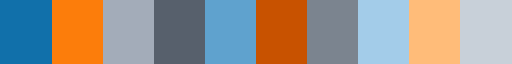

In [40]:
cmap

### Scatter plots

Saved plot to /Users/martinimarcello00/github-sync/SRE-agent/Results/all-apps-no-ablation-A-L/plots/001_scatter_detection_accuracy.pdf


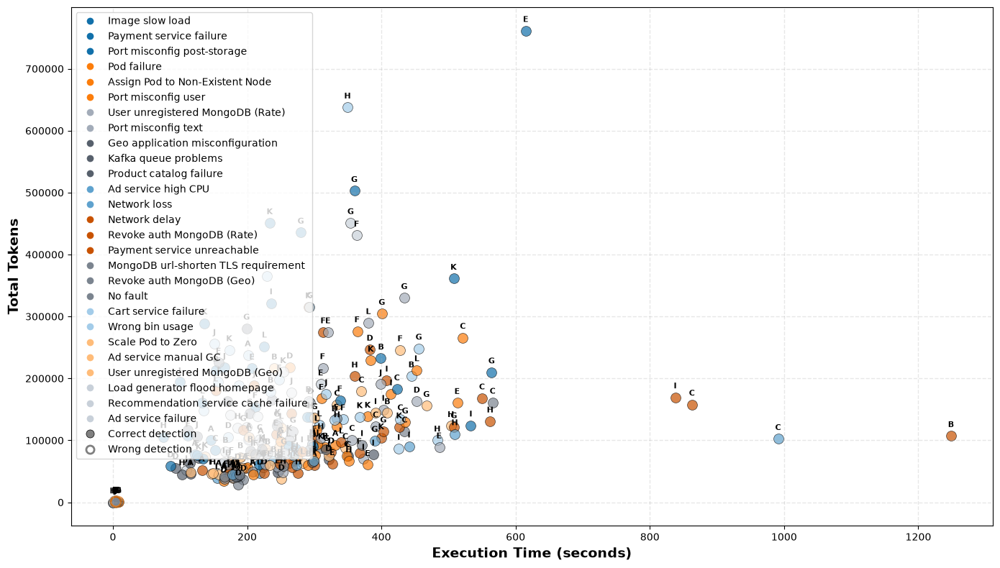

In [41]:
import matplotlib.pyplot as plt
import numpy as np

# Create figure and axis
fig, ax = plt.subplots(figsize=(14, 8))

# Get unique fault types for coloring
fault_types = experiments_df['fault_name'].unique()
colors = cmap(np.linspace(0, 1, len(fault_types)))
color_map = {fault: colors[i] for i, fault in enumerate(fault_types)}

# Plot each experiment as a dot
for idx, row in experiments_df.iterrows():
    x = row['execution_time_seconds']
    y = row['total_tokens']
    fault = row['fault_name']
    color = color_map[fault]
    detection = row['eval_detection']
    
    # Plot the dot - filled if detection is True, only border if False
    if detection:
        ax.scatter(x, y, s=100, color=color, alpha=0.7, edgecolors='black', linewidth=0.5)
    else:
        ax.scatter(x, y, s=100, facecolors='none', edgecolors=color, linewidth=2, alpha=0.7)
    
    # Add label with agent configuration on top of the dot
    label = f"{row['agent_id']}"
    ax.annotate(label, (x, y), fontsize=8, ha='center', va='bottom', fontweight='bold', 
                xytext=(0, 7), textcoords='offset points')

# Create legend for fault types
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[fault], 
                       markersize=8, label=fault) for fault in fault_types]

# Add detection legend
detection_handles = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', 
               markersize=8, label='Correct detection', markeredgecolor='black', markeredgewidth=0.5),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='none', 
               markersize=8, label='Wrong detection', markeredgecolor='gray', markeredgewidth=2)
]

# Combine all handles into a single legend
all_handles = handles + detection_handles
ax.legend(handles=all_handles, loc='upper left', fontsize=10)

# Labels and title
ax.set_xlabel('Execution Time (seconds)', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')
ax.set_ylabel('Total Tokens', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')
if SHOW_TITLE:
    ax.set_title(f'Detection Accuracy: Execution Time vs Token Usage - {SCENARIOS_NAME.title()}', fontsize=FONT_SIZE_TITLE, fontweight='bold')

# Grid
ax.grid(True, alpha=0.3, linestyle='--', linewidth=1)

plt.tight_layout()
if SAVE_IMAGES:
    plot_counter += 1
    filename = os.path.join(plots_dir, f'{plot_counter:03d}_scatter_detection_accuracy.pdf')

    fig.savefig(filename, format='pdf', bbox_inches='tight')

    print(f"Saved plot to {filename}")
plt.show()

Saved plot to /Users/martinimarcello00/github-sync/SRE-agent/Results/all-apps-no-ablation-A-L/plots/002_scatter_localization_accuracy.pdf


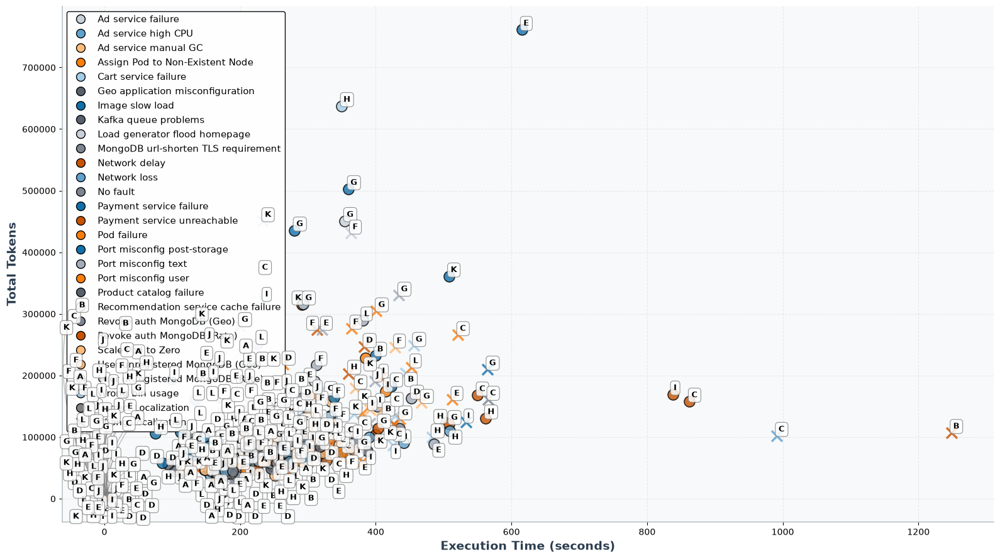

In [42]:
import matplotlib.pyplot as plt
import numpy as np
from adjustText import adjust_text

# Create figure and axis
fig, ax = plt.subplots(figsize=(16, 9))

# Get unique fault types for coloring
fault_types = experiments_df['fault_name'].unique()
colors = cmap(np.linspace(0, 1, len(fault_types)))
color_map = {fault: colors[i] for i, fault in enumerate(fault_types)}

# Collect points and labels for later adjustment
texts = []

# Plot each experiment as a dot
for idx, row in experiments_df.iterrows():
    x = row['execution_time_seconds']
    y = row['total_tokens']
    fault = row['fault_name']
    color = color_map[fault]
    correct_localization = row['eval_localization']
    
    # Plot the dot - filled if correct_localization is True, X marker if False
    if correct_localization:
        ax.scatter(x, y, s=150, color=color, alpha=0.8, edgecolors='black', linewidth=1.2)
    else:
        ax.scatter(x, y, s=150, marker='x', color=color, linewidth=2.5, alpha=0.8)
    
    # Add label with agent configuration
    label = f"{row['agent_id']}"
    text_obj = ax.text(x, y, label, fontsize=9, ha='center', va='center', fontweight='bold',
                       bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='gray', alpha=0.85, linewidth=0.8),
                       zorder=10)
    texts.append(text_obj)

# Adjust text positions to avoid overlaps
try:
    adjust_text(texts, arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0.2', 
                                       lw=0.8, color='gray', alpha=0.6),
                ax=ax, precision=0.1, expand_points=(1.5, 1.5))
except ImportError:
    print("Note: adjustText not installed. Labels may overlap. Install with: pip install adjustText")

# Create legend for fault types
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[fault], 
                       markersize=10, label=fault, markeredgecolor='black', markeredgewidth=1) 
           for fault in sorted(fault_types)]

# Add localization legend
localization_handles = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', 
               markersize=10, label='Correct Localization', markeredgecolor='black', markeredgewidth=1),
    plt.Line2D([0], [0], marker='x', color='gray', linestyle='None',
               markersize=10, label='Wrong Localization', markeredgewidth=2.5)
]

# Combine all handles into a single legend
all_handles = handles + localization_handles
ax.legend(handles=all_handles, loc='upper left', fontsize=11, framealpha=0.95, edgecolor='black')

# Labels and title
ax.set_xlabel('Execution Time (seconds)', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold', color='#2c3e50')
ax.set_ylabel('Total Tokens', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold', color='#2c3e50')
if SHOW_TITLE:
    ax.set_title(f'Localization Accuracy: Execution Time vs Token Usage - {SCENARIOS_NAME.title()}\n(by Fault Type and Agent Configuration)', 
                 fontsize=FONT_SIZE_TITLE, fontweight='bold', pad=20, color='#2c3e50')

# Grid and background
ax.set_facecolor('#f8f9fa')
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.8, color='#bdc3c7')
ax.set_axisbelow(True)

# Spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#bdc3c7')
ax.spines['bottom'].set_color('#bdc3c7')
ax.spines['left'].set_linewidth(1.2)
ax.spines['bottom'].set_linewidth(1.2)

plt.tight_layout()
if SAVE_IMAGES:
    plot_counter += 1
    filename = os.path.join(plots_dir, f'{plot_counter:03d}_scatter_localization_accuracy.pdf')

    fig.savefig(filename, format='pdf', bbox_inches='tight')

    print(f"Saved plot to {filename}")
plt.show()

Saved plot to /Users/martinimarcello00/github-sync/SRE-agent/Results/all-apps-no-ablation-A-L/plots/003_scatter_rca_score.pdf


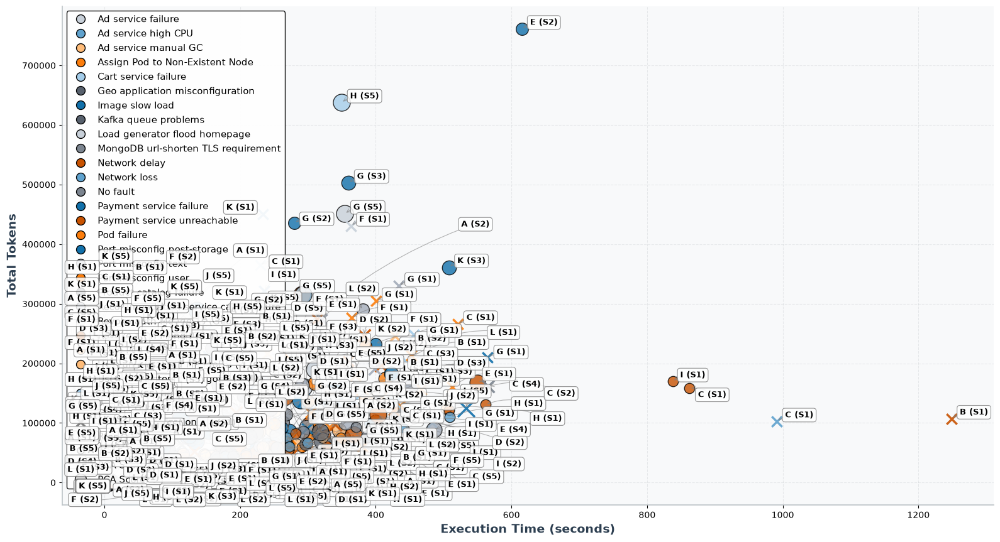

In [43]:
from adjustText import adjust_text

# Visualization: RCA score vs Execution Time and Token Usage

# Use existing variables: experiments_df, cmap, plt, np
fig, ax = plt.subplots(figsize=(16, 9))

# Color by fault type (reuse palette)
fault_types = experiments_df['fault_name'].unique()
colors = cmap(np.linspace(0, 1, len(fault_types)))
color_map = {fault: colors[i] for i, fault in enumerate(fault_types)}

# Point size encodes RCA score (0–5); shape encodes correctness of localization
def size_for_score(score: int) -> float:
    # Base size + scale; ensure visible even for low scores
    return 80 + 60 * max(0, int(score))

texts = []

for _, row in experiments_df.iterrows():
    x = row['execution_time_seconds']
    y = row['total_tokens']
    fault = row['fault_name']
    score = row['eval_rca_score']
    correct_loc = row['eval_localization']
    color = color_map[fault]
    s = size_for_score(score)

    # Circle for correct localization, 'x' for incorrect
    if correct_loc:
        ax.scatter(x, y, s=s, color=color, alpha=0.8, edgecolors='black', linewidth=1.0)
    else:
        ax.scatter(x, y, s=s, marker='x', color=color, linewidth=2.5, alpha=0.9)

    # Label with agent_id and score
    label = f"{row['agent_id']} (S{score})"
    text = ax.text(x, y, label, fontsize=9, ha='center', va='center', fontweight='bold',
                   bbox=dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='gray', alpha=0.85, linewidth=0.8),
                   zorder=10)
    texts.append(text)

# Optional: adjust_text if already imported above
try:
    adjust_text(texts, arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0.2',
                                       lw=0.8, color='gray', alpha=0.6),
                ax=ax, precision=0.1, expand_points=(1.5, 1.5))
except Exception:
    pass

# Legend: fault type colors
fault_handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[f],
                            markeredgecolor='black', markeredgewidth=1, markersize=10, label=f)
                 for f in sorted(fault_types)]

# Legend: localization correctness
loc_handles = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
               markeredgecolor='black', markeredgewidth=1, markersize=10, label='Correct Localization'),
    plt.Line2D([0], [0], marker='x', color='gray', linestyle='None',
               markeredgewidth=2.5, markersize=10, label='Incorrect Localization'),
]

# Legend: RCA score sizes (show exemplars)
score_examples = [0, 1, 3, 5]
size_handles = [plt.Line2D([0], [0], marker='o', color='w',
                           markerfacecolor='lightgray', markeredgecolor='black',
                           markeredgewidth=1, markersize=np.sqrt(size_for_score(s))/1.5,
                           label=f'RCA Score: {s}') for s in score_examples]

all_handles = fault_handles + loc_handles + size_handles
ax.legend(handles=all_handles, loc='upper left', fontsize=11, framealpha=0.95, edgecolor='black')

# Axes styling
ax.set_xlabel('Execution Time (seconds)', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold', color='#2c3e50')
ax.set_ylabel('Total Tokens', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold', color='#2c3e50')
if SHOW_TITLE:
    ax.set_title(f'RCA Score Visualization: Execution Time vs Token Usage - {SCENARIOS_NAME.title()}\n(size encodes RCA score; color by Fault Type)',
             fontsize=FONT_SIZE_TITLE, fontweight='bold', pad=20, color='#2c3e50')

ax.set_facecolor('#f8f9fa')
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.8, color='#bdc3c7')
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#bdc3c7')
ax.spines['bottom'].set_color('#bdc3c7')
ax.spines['left'].set_linewidth(1.2)
ax.spines['bottom'].set_linewidth(1.2)

plt.tight_layout()
if SAVE_IMAGES:
    plot_counter += 1
    filename = os.path.join(plots_dir, f'{plot_counter:03d}_scatter_rca_score.pdf')

    fig.savefig(filename, format='pdf', bbox_inches='tight')

    print(f"Saved plot to {filename}")
plt.show()

### Box plots

Saved plot to /Users/martinimarcello00/github-sync/SRE-agent/Results/all-apps-no-ablation-A-L/plots/004_boxplot_global_distribution.pdf


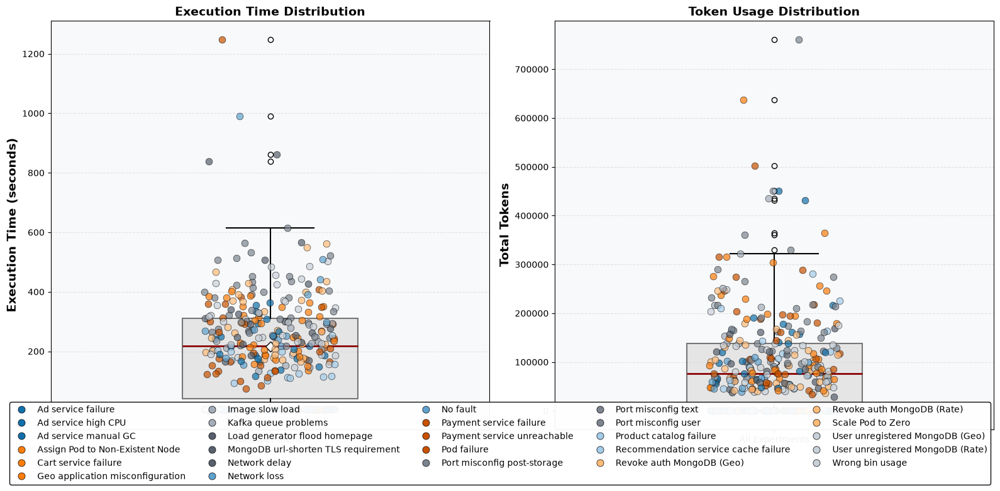

In [44]:
# Create figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Prepare all data for global box plots
all_time_data = experiments_df['execution_time_seconds'].values
all_token_data = experiments_df['total_tokens'].values

# Get unique fault types for coloring individual points
fault_types = sorted(experiments_df['fault_name'].unique())
colors_array = cmap(np.linspace(0, 1, len(fault_types)))
color_map = {fault: colors_array[i] for i, fault in enumerate(fault_types)}

# Box plot for execution time (global)
bp1 = axes[0].boxplot([all_time_data], tick_labels=['All Experiments'], patch_artist=True, 
                      widths=0.4, showmeans=True,
                      boxprops=dict(linewidth=1.5),
                      whiskerprops=dict(linewidth=1.5),
                      capprops=dict(linewidth=1.5),
                      medianprops=dict(linewidth=2, color='darkred'),
                      meanprops=dict(marker='D', markerfacecolor='white', 
                                    markeredgecolor='black', markersize=8))

bp1['boxes'][0].set_facecolor('lightgray')
bp1['boxes'][0].set_alpha(0.5)

# Overlay individual experiments as dots
for idx, row in experiments_df.iterrows():
    fault = row['fault_name']
    color = color_map[fault]
    # Add small jitter to x position for visibility
    x_pos = 1 + np.random.uniform(-0.15, 0.15)
    axes[0].scatter(x_pos, row['execution_time_seconds'], s=60, color=color, 
                   alpha=0.7, edgecolors='black', linewidth=0.5, zorder=3)

axes[0].set_ylabel('Execution Time (seconds)', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')
axes[0].set_title('Execution Time Distribution', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')
axes[0].grid(True, alpha=0.3, linestyle='--', axis='y')
axes[0].set_facecolor('#f8f9fa')
axes[0].set_xlim(0.5, 1.5)

# Box plot for token usage (global)
bp2 = axes[1].boxplot([all_token_data], tick_labels=['All Experiments'], patch_artist=True,
                      widths=0.4, showmeans=True,
                      boxprops=dict(linewidth=1.5),
                      whiskerprops=dict(linewidth=1.5),
                      capprops=dict(linewidth=1.5),
                      medianprops=dict(linewidth=2, color='darkred'),
                      meanprops=dict(marker='D', markerfacecolor='white', 
                                    markeredgecolor='black', markersize=8))

bp2['boxes'][0].set_facecolor('lightgray')
bp2['boxes'][0].set_alpha(0.5)

# Overlay individual experiments as dots
for idx, row in experiments_df.iterrows():
    fault = row['fault_name']
    color = color_map[fault]
    x_pos = 1 + np.random.uniform(-0.15, 0.15)
    axes[1].scatter(x_pos, row['total_tokens'], s=60, color=color, 
                   alpha=0.7, edgecolors='black', linewidth=0.5, zorder=3)

axes[1].set_ylabel('Total Tokens', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')
axes[1].set_title('Token Usage Distribution', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')
axes[1].grid(True, alpha=0.3, linestyle='--', axis='y')
axes[1].set_facecolor('#f8f9fa')
axes[1].set_xlim(0.5, 1.5)

# Create legend for fault types (moved below the plots)
fault_handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[fault],
                            markeredgecolor='black', markeredgewidth=0.5, markersize=8, label=fault)
                 for fault in fault_types]
fig.legend(handles=fault_handles, loc='lower center', ncol=5, fontsize=10,
           framealpha=0.95, edgecolor='black', bbox_to_anchor=(0.5, -0.02))

# Add main title with scenarios
if SHOW_TITLE:
    fig.suptitle(f'Global Performance Distribution - {SCENARIOS_NAME.title()}', fontsize=16, fontweight='bold', y=0.98)

# Leave space at the bottom for the legend
plt.tight_layout(rect=[0, 0.05, 1, 0.96])
if SAVE_IMAGES:
    plot_counter += 1
    filename = os.path.join(plots_dir, f'{plot_counter:03d}_boxplot_global_distribution.pdf')

    fig.savefig(filename, format='pdf', bbox_inches='tight')

    print(f"Saved plot to {filename}")
plt.show()

Saved plot to /Users/martinimarcello00/github-sync/SRE-agent/Results/all-apps-no-ablation-A-L/plots/005_boxplot_by_fault_type.pdf


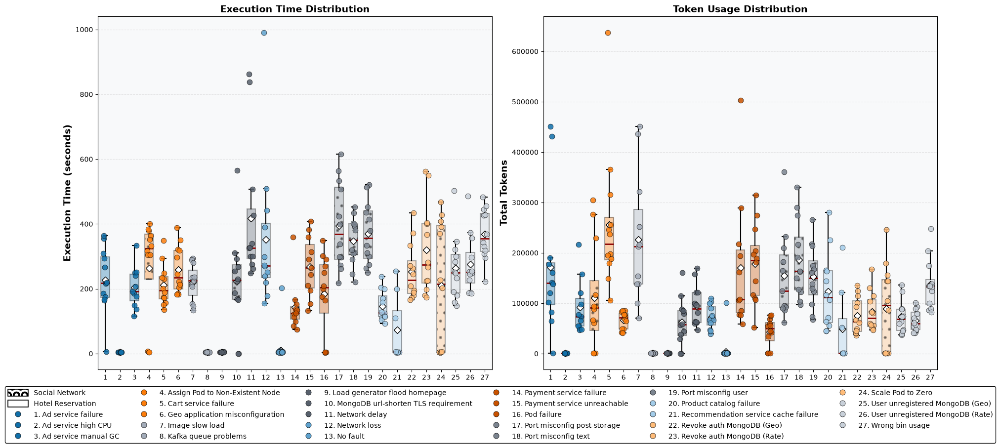

In [45]:
import matplotlib as mpl
import matplotlib.patches as mpatches

# Make hatches more visible in legend
mpl.rcParams['hatch.linewidth'] = 2.2

# Prepare data grouped by fault_name for per-fault box plots
fault_types = sorted(experiments_df['fault_name'].unique())
colors_array = cmap(np.linspace(0, 1, len(fault_types)))
color_map = {fault: colors_array[i] for i, fault in enumerate(fault_types)}

# Outlier thresholds
MAX_TIME = 1000  # seconds
MAX_TOKENS = 700000  # token usage

# Determine hatch per fault based on scenario if available
has_scenario_col = 'scenario' in experiments_df.columns
hatch_map = {}
if has_scenario_col:
    for fault in fault_types:
        scen_vals = experiments_df.loc[experiments_df['fault_name'] == fault, 'scenario'].astype(str).str.lower()
        # Use majority scenario label for this fault
        scen = scen_vals.mode().iloc[0] if len(scen_vals) else ''
        hatch_map[fault] = '.' if 'social' in scen else None
else:
    # Fallback: use SCENARIOS_NAME string (applies same style to all faults)
    is_social = 'social' in SCENARIOS_NAME.lower()
    for fault in fault_types:
        hatch_map[fault] = '.' if is_social else None

# Build per-fault arrays with outlier filtering
time_data = [
    experiments_df[(experiments_df['fault_name'] == fault) &
                   (experiments_df['execution_time_seconds'] < MAX_TIME)]['execution_time_seconds'].values
    for fault in fault_types
]
token_data = [
    experiments_df[(experiments_df['fault_name'] == fault) &
                   (experiments_df['total_tokens'] <= MAX_TOKENS)]['total_tokens'].values
    for fault in fault_types
]

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

# Create tick labels with numbers
tick_labels = [f"{i+1}" for i in range(len(fault_types))]

# Execution time per fault
bp_time = axes[0].boxplot(
    time_data,
    tick_labels=tick_labels,
    patch_artist=True,
    widths=0.6,
    showmeans=True,
    showfliers=False,
    boxprops=dict(linewidth=1.5),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5),
    medianprops=dict(linewidth=2, color='darkred'),
    meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black', markersize=7)
)
# Color boxes by fault type and apply scenario-based hatch
for i, box in enumerate(bp_time['boxes']):
    fault = fault_types[i]
    box.set_facecolor(color_map[fault])
    box.set_alpha(0.35)
    if hatch_map.get(fault):
        box.set_hatch(hatch_map[fault])

# Overlay individual points with jitter per fault (filtered)
for i, fault in enumerate(fault_types, start=1):
    data = experiments_df[experiments_df['fault_name'] == fault]
    data_time = data[data['execution_time_seconds'] < MAX_TIME]
    jitter_x = i + np.random.uniform(-0.15, 0.15, size=len(data_time))
    axes[0].scatter(
        jitter_x,
        data_time['execution_time_seconds'],
        s=60,
        color=color_map[fault],
        alpha=0.85,
        edgecolors='black',
        linewidth=0.5,
        zorder=3
    )

axes[0].set_ylabel('Execution Time (seconds)', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')
axes[0].set_title('Execution Time Distribution', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')
axes[0].grid(True, alpha=0.3, linestyle='--', axis='y')
axes[0].set_facecolor('#f8f9fa')

# Tokens per fault
bp_tokens = axes[1].boxplot(
    token_data,
    tick_labels=tick_labels,
    patch_artist=True,
    widths=0.6,
    showmeans=True,
    showfliers=False,
    boxprops=dict(linewidth=1.5),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5),
    medianprops=dict(linewidth=2, color='darkred'),
    meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black', markersize=7)
)
for i, box in enumerate(bp_tokens['boxes']):
    fault = fault_types[i]
    box.set_facecolor(color_map[fault])
    box.set_alpha(0.35)
    if hatch_map.get(fault):
        box.set_hatch(hatch_map[fault])

for i, fault in enumerate(fault_types, start=1):
    data = experiments_df[experiments_df['fault_name'] == fault]
    data_tokens = data[data['total_tokens'] <= MAX_TOKENS]
    jitter_x = i + np.random.uniform(-0.15, 0.15, size=len(data_tokens))
    axes[1].scatter(
        jitter_x,
        data_tokens['total_tokens'],
        s=60,
        color=color_map[fault],
        alpha=0.85,
        edgecolors='black',
        linewidth=0.5,
        zorder=3
    )

axes[1].set_ylabel('Total Tokens', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')
axes[1].set_title('Token Usage Distribution', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')
axes[1].grid(True, alpha=0.3, linestyle='--', axis='y')
axes[1].set_facecolor('#f8f9fa')

# Create legend with numbers and fault names
fault_handles = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[fault],
                markeredgecolor='black', markeredgewidth=0.5, markersize=8,
                label=f"{i+1}. {fault}")
    for i, fault in enumerate(fault_types)
]

# Dataset style legend handles (larger dots and handle size)
style_handles = [
    mpatches.Patch(facecolor='white', hatch='O', edgecolor='black', linewidth=1.2, alpha=1.0, label='Social Network'),
    mpatches.Patch(facecolor='white', hatch=None, edgecolor='black', linewidth=1.2, alpha=1.0, label='Hotel Reservation'),
]

fig.legend(handles=style_handles + fault_handles, loc='lower center', ncol=6, fontsize=10,
           framealpha=0.95, edgecolor='black', bbox_to_anchor=(0.5, -0.05),
           handlelength=3.0, handleheight=1.2)

# Add main title with scenarios
if SHOW_TITLE:
    fig.suptitle(f'Performance Distribution by Fault Type - {SCENARIOS_NAME.title()}', fontsize=FONT_SIZE_TITLE, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0.08, 1, 0.96])
if SAVE_IMAGES:
    plot_counter += 1
    filename = os.path.join(plots_dir, f'{plot_counter:03d}_boxplot_by_fault_type.pdf')

    fig.savefig(filename, format='pdf', bbox_inches='tight')

    print(f"Saved plot to {filename}")
plt.show()

Saved plot to /Users/martinimarcello00/github-sync/SRE-agent/Results/all-apps-no-ablation-A-L/plots/006_boxplot_by_agent_type.pdf


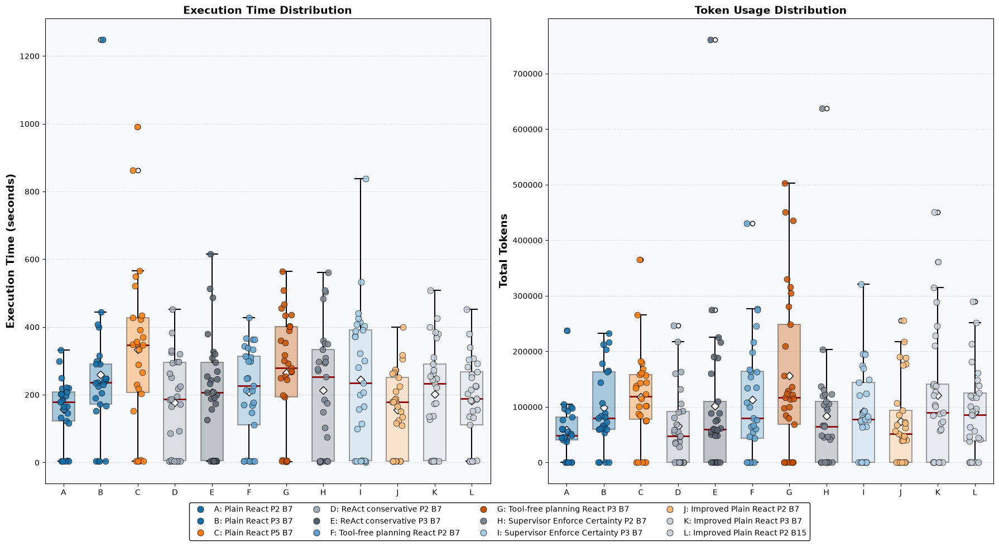

In [46]:
# Box plots by agent type (agent_id)

# Prepare data grouped by agent_id
agent_types = sorted(experiments_df['agent_id'].unique())
colors_array = cmap(np.linspace(0, 1, len(agent_types)))
agent_color_map = {agent: colors_array[i] for i, agent in enumerate(agent_types)}

time_data_agent = [
    experiments_df[experiments_df['agent_id'] == agent]['execution_time_seconds'].values
    for agent in agent_types
]
token_data_agent = [
    experiments_df[experiments_df['agent_id'] == agent]['total_tokens'].values
    for agent in agent_types
]

fig, axes = plt.subplots(1, 2, figsize=(18, 10))

# Execution time per agent
bp_time = axes[0].boxplot(
    time_data_agent,
    tick_labels=agent_types,
    patch_artist=True,
    widths=0.6,
    showmeans=True,
    boxprops=dict(linewidth=1.5),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5),
    medianprops=dict(linewidth=2, color='darkred'),
    meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black', markersize=7)
)
for i, box in enumerate(bp_time['boxes']):
    box.set_facecolor(agent_color_map[agent_types[i]])
    box.set_alpha(0.35)

# Overlay individual points with jitter per agent
for i, agent in enumerate(agent_types, start=1):
    data = experiments_df[experiments_df['agent_id'] == agent]
    jitter_x = i + np.random.uniform(-0.15, 0.15, size=len(data))
    axes[0].scatter(
        jitter_x,
        data['execution_time_seconds'],
        s=60,
        color=agent_color_map[agent],
        alpha=0.85,
        edgecolors='black',
        linewidth=0.5,
        zorder=3
    )

axes[0].set_ylabel('Execution Time (seconds)', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')
axes[0].set_title('Execution Time Distribution', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')
axes[0].grid(True, alpha=0.3, linestyle='--', axis='y')
axes[0].set_facecolor('#f8f9fa')

# Tokens per agent
bp_tokens = axes[1].boxplot(
    token_data_agent,
    tick_labels=agent_types,
    patch_artist=True,
    widths=0.6,
    showmeans=True,
    boxprops=dict(linewidth=1.5),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5),
    medianprops=dict(linewidth=2, color='darkred'),
    meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black', markersize=7)
)
for i, box in enumerate(bp_tokens['boxes']):
    box.set_facecolor(agent_color_map[agent_types[i]])
    box.set_alpha(0.35)

for i, agent in enumerate(agent_types, start=1):
    data = experiments_df[experiments_df['agent_id'] == agent]
    jitter_x = i + np.random.uniform(-0.15, 0.15, size=len(data))
    axes[1].scatter(
        jitter_x,
        data['total_tokens'],
        s=60,
        color=agent_color_map[agent],
        alpha=0.85,
        edgecolors='black',
        linewidth=0.5,
        zorder=3
    )

axes[1].set_ylabel('Total Tokens', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')
axes[1].set_title('Token Usage Distribution', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')
axes[1].grid(True, alpha=0.3, linestyle='--', axis='y')
axes[1].set_facecolor('#f8f9fa')

for ax in axes:
    ax.tick_params(axis='x', rotation=0)

# Legend for agent types
agent_handles = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor=agent_color_map[agent],
               markeredgecolor='black', markeredgewidth=0.5,
               markersize=8, label=f'{agent}: {agent_desc_dict[agent]["name"]}')
    for agent in agent_types
]
fig.legend(handles=agent_handles, loc='lower center', ncol=4, fontsize=10,
           framealpha=0.95, edgecolor='black', bbox_to_anchor=(0.5, -0.02))

# Add main title with scenarios
if SHOW_TITLE:
    fig.suptitle(f'Performance Distribution by Agent Configuration - {SCENARIOS_NAME.title()}', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0.05, 1, 0.96])
if SAVE_IMAGES:
    plot_counter += 1
    filename = os.path.join(plots_dir, f'{plot_counter:03d}_boxplot_by_agent_type.pdf')

    fig.savefig(filename, format='pdf', bbox_inches='tight')

    print(f"Saved plot to {filename}")
plt.show()

### Pie Chart Tool calls distributions


Saved plot to /Users/martinimarcello00/github-sync/SRE-agent/Results/all-apps-no-ablation-A-L/plots/007_pie_tool_calls_by_agent_detailed.pdf


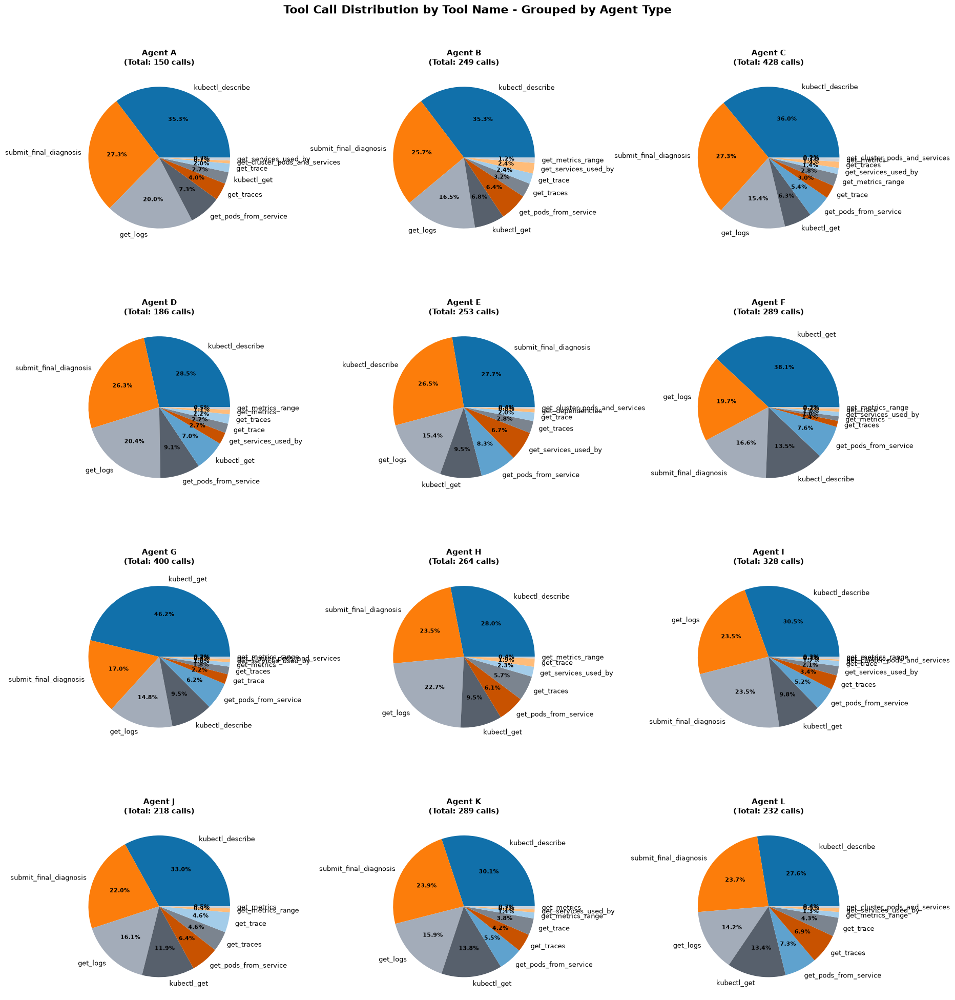

In [47]:
# ============================================
# 1. Tool Calls by Tool Name - Filtered by Agent Type
# ============================================

agent_types = sorted(experiments_df['agent_id'].unique())

# Create subplots for each agent
num_agents = len(agent_types)
num_cols = 3
num_rows = (num_agents + num_cols - 1) // num_cols

fig, axes = plt.subplots(num_rows, num_cols, figsize=(18, 5*num_rows))
axes = axes.flatten()  # Flatten for easier indexing

# Store dataframes for each agent
agent_tool_dfs = {}

for idx, agent in enumerate(agent_types):
    agent_data = experiments_df[experiments_df['agent_id'] == agent]
    
    # Aggregate tool counts for this agent
    tool_counts = {}
    for _, row in agent_data.iterrows():
        if isinstance(row['tool_call_counts'], dict):
            for tool_name, count in row['tool_call_counts'].items():
                tool_counts[tool_name] = tool_counts.get(tool_name, 0) + count
    
    # Create dataframe
    df_agent_tool = pd.DataFrame({
        'Tool': list(tool_counts.keys()),
        'Calls': list(tool_counts.values())
    })
    df_agent_tool['Percentage'] = (df_agent_tool['Calls'] / df_agent_tool['Calls'].sum() * 100).round(2)
    df_agent_tool = df_agent_tool.sort_values('Calls', ascending=False)
    
    agent_tool_dfs[agent] = df_agent_tool
    
    # Plot pie chart with cmap palette
    ax = axes[idx]
    colors = cmap(np.linspace(0, 1, len(df_agent_tool)))
    wedges, texts, autotexts = ax.pie(
        df_agent_tool['Calls'],
        labels=df_agent_tool['Tool'],
        autopct='%1.1f%%',
        colors=colors,
        textprops={'fontsize': 9}
    )
    
    for autotext in autotexts:
        autotext.set_color('black')
        autotext.set_fontsize(8)
        autotext.set_weight('bold')
    
    ax.set_title(f'Agent {agent}\n(Total: {df_agent_tool["Calls"].sum()} calls)', 
                 fontsize=11, fontweight='bold')
    
# Remove extra subplots
for idx in range(num_agents, len(axes)):
    fig.delaxes(axes[idx])

fig.suptitle('Tool Call Distribution by Tool Name - Grouped by Agent Type', 
             fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
if SAVE_IMAGES:
    plot_counter += 1
    filename = os.path.join(plots_dir, f'{plot_counter:03d}_pie_tool_calls_by_agent_detailed.pdf')
    fig.savefig(filename, format='pdf', bbox_inches='tight')
    print(f"\nSaved plot to {filename}")
plt.show()


In [48]:
agent_tool_dfs

{'A':                             Tool  Calls  Percentage
 2               kubectl_describe     53       35.33
 1         submit_final_diagnosis     41       27.33
 3                       get_logs     30       20.00
 4          get_pods_from_service     11        7.33
 0                     get_traces      6        4.00
 8                    kubectl_get      4        2.67
 5                      get_trace      3        2.00
 6  get_cluster_pods_and_services      1        0.67
 7           get_services_used_by      1        0.67,
 'B':                      Tool  Calls  Percentage
 3        kubectl_describe     88       35.34
 2  submit_final_diagnosis     64       25.70
 1                get_logs     41       16.47
 4             kubectl_get     17        6.83
 0   get_pods_from_service     16        6.43
 6              get_traces      8        3.21
 7               get_trace      6        2.41
 8    get_services_used_by      6        2.41
 5       get_metrics_range      3        1.20


Ad service failure:
                  Tool  Calls  Percentage
submit_final_diagnosis     38       23.31
              get_logs     32       19.63
      kubectl_describe     30       18.40
           kubectl_get     22       13.50
 get_pods_from_service     20       12.27
            get_traces      6        3.68
             get_trace      6        3.68
  get_services_used_by      5        3.07
           get_metrics      3        1.84
     get_metrics_range      1        0.61

Ad service manual GC:
                         Tool  Calls  Percentage
       submit_final_diagnosis     33       28.45
             kubectl_describe     32       27.59
                  kubectl_get     19       16.38
                     get_logs     10        8.62
         get_services_used_by      6        5.17
        get_pods_from_service      6        5.17
                   get_traces      3        2.59
            get_metrics_range      3        2.59
                    get_trace      2        1.72
    


Saved plot to /Users/martinimarcello00/github-sync/SRE-agent/Results/all-apps-no-ablation-A-L/plots/008_pie_tool_calls_by_fault_detailed.pdf


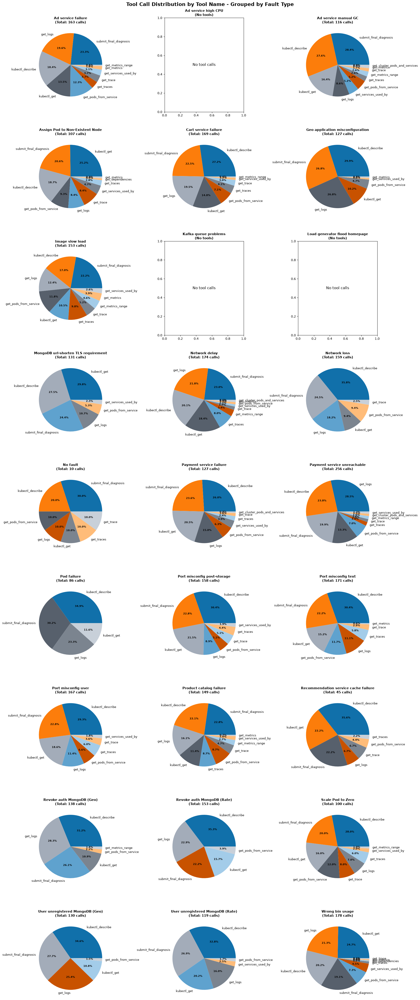

In [49]:
fault_types = sorted(experiments_df['fault_name'].unique())

# Create subplots for each fault
num_faults = len(fault_types)
num_cols = 3
num_rows = (num_faults + num_cols - 1) // num_cols

fig, axes = plt.subplots(num_rows, num_cols, figsize=(18, 5*num_rows))
axes = axes.flatten()

fault_tool_dfs = {}

for idx, fault in enumerate(fault_types):
    fault_data = experiments_df[experiments_df['fault_name'] == fault]
    
    # Aggregate tool counts for this fault
    tool_counts = {}
    for _, row in fault_data.iterrows():
        if isinstance(row['tool_call_counts'], dict):
            for tool_name, count in row['tool_call_counts'].items():
                tool_counts[tool_name] = tool_counts.get(tool_name, 0) + count
    
    # Create dataframe
    df_fault_tool = pd.DataFrame({
        'Tool': list(tool_counts.keys()),
        'Calls': list(tool_counts.values())
    })
    
    if len(df_fault_tool) > 0:
        df_fault_tool['Percentage'] = (df_fault_tool['Calls'] / df_fault_tool['Calls'].sum() * 100).round(2)
        df_fault_tool = df_fault_tool.sort_values('Calls', ascending=False)
    
    fault_tool_dfs[fault] = df_fault_tool
    
    # Plot pie chart
    ax = axes[idx]
    
    if len(df_fault_tool) > 0 and df_fault_tool['Calls'].sum() > 0:
        colors = cmap(np.linspace(0, 1, len(df_fault_tool)))
        wedges, texts, autotexts = ax.pie(
            df_fault_tool['Calls'],
            labels=df_fault_tool['Tool'],
            autopct='%1.1f%%',
            colors=colors,
            textprops={'fontsize': 9}
        )
        
        for autotext in autotexts:
            autotext.set_color('black')
            autotext.set_fontsize(8)
            autotext.set_weight('bold')
        
        ax.set_title(f'{fault}\n(Total: {df_fault_tool["Calls"].sum()} calls)', 
                     fontsize=11, fontweight='bold')
        
        print(f"\n{fault}:")
        print(df_fault_tool.to_string(index=False))
    else:
        ax.text(0.5, 0.5, 'No tool calls', ha='center', va='center', fontsize=12)
        ax.set_title(f'{fault}\n(No tools)', fontsize=11, fontweight='bold')

# Remove extra subplots
for idx in range(num_faults, len(axes)):
    fig.delaxes(axes[idx])

fig.suptitle('Tool Call Distribution by Tool Name - Grouped by Fault Type', 
             fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
if SAVE_IMAGES:
    plot_counter += 1
    filename = os.path.join(plots_dir, f'{plot_counter:03d}_pie_tool_calls_by_fault_detailed.pdf')
    fig.savefig(filename, format='pdf', bbox_inches='tight')
    print(f"\nSaved plot to {filename}")
plt.show()


Saved plot to /Users/martinimarcello00/github-sync/SRE-agent/Results/all-apps-no-ablation-A-L/plots/009_pie_tool_calls_by_localization.pdf


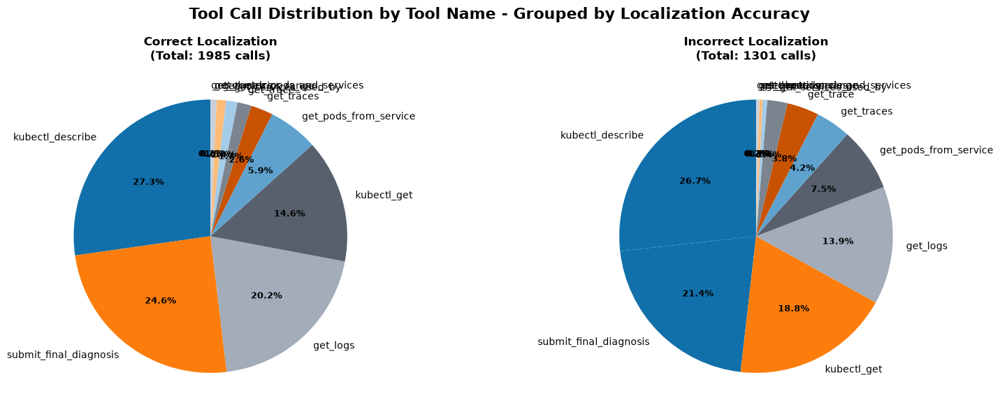

In [50]:
localization_groups = ['Correct Localization', 'Incorrect Localization']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

localization_tool_dfs = {}

# Correct localization
correct_data = experiments_df[experiments_df['eval_localization'] == True]
tool_counts_correct = {}
for _, row in correct_data.iterrows():
    if isinstance(row['tool_call_counts'], dict):
        for tool_name, count in row['tool_call_counts'].items():
            tool_counts_correct[tool_name] = tool_counts_correct.get(tool_name, 0) + count

df_correct = pd.DataFrame({
    'Tool': list(tool_counts_correct.keys()),
    'Calls': list(tool_counts_correct.values())
})
if len(df_correct) > 0:
    df_correct['Percentage'] = (df_correct['Calls'] / df_correct['Calls'].sum() * 100).round(2)
    df_correct = df_correct.sort_values('Calls', ascending=False)

localization_tool_dfs['Correct'] = df_correct

ax = axes[0]
colors = cmap(np.linspace(0, 1, len(df_correct)))
wedges, texts, autotexts = ax.pie(
    df_correct['Calls'],
    labels=df_correct['Tool'],
    autopct='%1.1f%%',
    colors=colors,
    textprops={'fontsize': 10},
    startangle=90
)

for autotext in autotexts:
    autotext.set_color('black')
    autotext.set_fontsize(9)
    autotext.set_weight('bold')

ax.set_title(f'Correct Localization\n(Total: {df_correct["Calls"].sum()} calls)', 
             fontsize=12, fontweight='bold')


# Incorrect localization
incorrect_data = experiments_df[experiments_df['eval_localization'] == False]
tool_counts_incorrect = {}
for _, row in incorrect_data.iterrows():
    if isinstance(row['tool_call_counts'], dict):
        for tool_name, count in row['tool_call_counts'].items():
            tool_counts_incorrect[tool_name] = tool_counts_incorrect.get(tool_name, 0) + count

df_incorrect = pd.DataFrame({
    'Tool': list(tool_counts_incorrect.keys()),
    'Calls': list(tool_counts_incorrect.values())
})
if len(df_incorrect) > 0:
    df_incorrect['Percentage'] = (df_incorrect['Calls'] / df_incorrect['Calls'].sum() * 100).round(2)
    df_incorrect = df_incorrect.sort_values('Calls', ascending=False)

localization_tool_dfs['Incorrect'] = df_incorrect

ax = axes[1]
if len(df_incorrect) > 0:
    colors = cmap(np.linspace(0, 1, len(df_incorrect)))
    wedges, texts, autotexts = ax.pie(
        df_incorrect['Calls'],
        labels=df_incorrect['Tool'],
        autopct='%1.1f%%',
        colors=colors,
        textprops={'fontsize': 10},
        startangle=90
    )
    
    for autotext in autotexts:
        autotext.set_color('black')
        autotext.set_fontsize(9)
        autotext.set_weight('bold')
    
    ax.set_title(f'Incorrect Localization\n(Total: {df_incorrect["Calls"].sum()} calls)', 
                 fontsize=12, fontweight='bold')
    

else:
    ax.text(0.5, 0.5, 'No tool calls', ha='center', va='center', fontsize=12)
    ax.set_title(f'Incorrect Localization\n(No tools)', fontsize=12, fontweight='bold')

fig.suptitle('Tool Call Distribution by Tool Name - Grouped by Localization Accuracy', 
             fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
if SAVE_IMAGES:
    plot_counter += 1
    filename = os.path.join(plots_dir, f'{plot_counter:03d}_pie_tool_calls_by_localization.pdf')
    fig.savefig(filename, format='pdf', bbox_inches='tight')
    print(f"\nSaved plot to {filename}")
plt.show()

### Interactive Visualization

In [51]:
import numpy as np

import plotly.graph_objects as go

# Prepare data
plot_df = experiments_df.copy()
plot_df['hover_text'] = plot_df.apply(lambda row: 
    f"<b>Agent:</b> {row['agent_id']}<br>"
    f"<b>Scenario:</b> {row['scenario']}<br>"
    f"<b>Fault:</b> {row['fault_name']}<br>"
    f"<b>Time:</b> {row['execution_time_seconds']:.1f}s<br>"
    f"<b>Tokens:</b> {int(row['total_tokens']):,}<br>"
    f"<b>Detection:</b> {'✓' if row['eval_detection'] else '✗'}<br>"
    f"<b>Localization:</b> {'✓' if row['eval_localization'] else '✗'}<br>"
    f"<b>RCA Score:</b> {row['eval_rca_score']}/5",
    axis=1
)

# Color palette from pypalettes
fault_types = sorted(plot_df['fault_name'].unique())
colors_array = cmap(np.linspace(0, 1, len(fault_types)))
color_map = {fault: f'rgba({int(c[0]*255)},{int(c[1]*255)},{int(c[2]*255)},0.8)' 
             for fault, c in zip(fault_types, colors_array)}

# Create figure
fig = go.Figure()

for fault in fault_types:
    data = plot_df[plot_df['fault_name'] == fault]

    # Partition by localization correctness (treat NaN as incorrect/missing)
    correct = data[data['eval_localization'] == True]
    incorrect = data[data['eval_localization'] == False]

    legend_shown = False

    # Correct localization (circles)
    if len(correct) > 0:
        fig.add_trace(go.Scatter(
            x=correct['execution_time_seconds'],
            y=correct['total_tokens'],
            mode='markers+text',
            name=fault,  # ensure one legend entry per fault
            marker=dict(
                size=correct['eval_rca_score'] * 8 + 15,
                color=color_map[fault],
                line=dict(width=2, color='white'),
                symbol='circle'
            ),
            text=correct['agent_id'],
            textposition='middle center',
            textfont=dict(size=10, color='white', family='Arial Black'),
            customdata=correct['hover_text'],
            hovertemplate='%{customdata}<extra></extra>',
            legendgroup=fault,
            showlegend=True
        ))
        legend_shown = True

    # Incorrect localization (X markers)
    if len(incorrect) > 0:
        # If no correct points exist, show this trace in legend under the fault name
        name_for_incorrect = fault if not legend_shown else f'{fault} (incorrect)'
        fig.add_trace(go.Scatter(
            x=incorrect['execution_time_seconds'],
            y=incorrect['total_tokens'],
            mode='markers+text',
            name=name_for_incorrect,
            marker=dict(
                size=incorrect['eval_rca_score'] * 8 + 15,
                color=color_map[fault],
                line=dict(width=3, color=color_map[fault]),
                symbol='x',
                opacity=0.6
            ),
            text=incorrect['agent_id'],
            textposition='middle center',
            textfont=dict(size=10, color=color_map[fault], family='Arial Black'),
            customdata=incorrect['hover_text'],
            hovertemplate='%{customdata}<extra></extra>',
            legendgroup=fault,
            showlegend=not legend_shown
        ))

fig.update_layout(
    title=dict(
        text='<b>Experiment Performance Dashboard</b><br><sub>Execution Time vs Token Usage | Size: RCA Score | Shape: Localization Accuracy</sub>',
        x=0.5,
        xanchor='center',
        font=dict(size=20, color='#2c3e50')
    ),
    xaxis=dict(
        title='<b>Execution Time (seconds)</b>',
        showgrid=True,
        gridcolor='rgba(200,200,200,0.3)',
        zeroline=False,
        title_font=dict(size=14, color='#34495e')
    ),
    yaxis=dict(
        title='<b>Total Tokens</b>',
        showgrid=True,
        gridcolor='rgba(200,200,200,0.3)',
        zeroline=False,
        title_font=dict(size=14, color='#34495e')
    ),
    plot_bgcolor='#f8f9fa',
    paper_bgcolor='white',
    height=750,
    hovermode='closest',
    font=dict(family='Arial, sans-serif', size=12),
    legend=dict(
        title=dict(text='<b>Fault Types</b>', font=dict(size=13)),
        orientation='v',
        yanchor='top',
        y=0.98,
        xanchor='left',
        x=0.01,
        bgcolor='rgba(255,255,255,0.9)',
        bordercolor='#bdc3c7',
        borderwidth=1
    ),
    margin=dict(l=80, r=30, t=100, b=80)
)

fig.show()

fig.write_html('/Users/martinimarcello00/github-sync/SRE-agent/Results/all-apps-no-ablation-A-L/analysis/performance_dashboard.html', include_plotlyjs=True)

In [52]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Interactive Box Plot by Fault Type
fault_types = sorted(experiments_df['fault_name'].unique())
colors_array = cmap(np.linspace(0, 1, len(fault_types)))
fault_color_map = {fault: f'rgba({int(c[0]*255)},{int(c[1]*255)},{int(c[2]*255)},0.8)' 
                   for fault, c in zip(fault_types, colors_array)}

fig_fault = make_subplots(rows=1, cols=2, 
                          subplot_titles=['<b>Execution Time by Fault Type</b>', 
                                         '<b>Token Usage by Fault Type</b>'],
                          horizontal_spacing=0.08)

for i, fault in enumerate(fault_types):
    data = experiments_df[experiments_df['fault_name'] == fault]
    color = fault_color_map[fault]
    
    # Hover text for individual points
    hover_texts = data.apply(lambda row: 
        f"<b>Agent:</b> {row['agent_id']}<br>"
        f"<b>Fault:</b> {row['fault_name']}<br>"
        f"<b>Time:</b> {row['execution_time_seconds']:.1f}s<br>"
        f"<b>Tokens:</b> {int(row['total_tokens']):,}<br>"
        f"<b>Detection:</b> {'✓' if row['eval_detection'] else '✗'}<br>"
        f"<b>Localization:</b> {'✓' if row['eval_localization'] else '✗'}<br>"
        f"<b>RCA Score:</b> {row['eval_rca_score']}/5",
        axis=1
    ).tolist()
    
    # Execution time box plot
    fig_fault.add_trace(go.Box(
        y=data['execution_time_seconds'],
        name=fault,
        marker_color=color,
        boxpoints='all',
        jitter=0.4,
        pointpos=0,
        marker=dict(size=8, opacity=0.7, line=dict(width=1, color='white')),
        hovertext=hover_texts,
        hoverinfo='text',
        legendgroup=fault,
        showlegend=True
    ), row=1, col=1)
    
    # Token usage box plot
    fig_fault.add_trace(go.Box(
        y=data['total_tokens'],
        name=fault,
        marker_color=color,
        boxpoints='all',
        jitter=0.4,
        pointpos=0,
        marker=dict(size=8, opacity=0.7, line=dict(width=1, color='white')),
        hovertext=hover_texts,
        hoverinfo='text',
        legendgroup=fault,
        showlegend=False
    ), row=1, col=2)

fig_fault.update_layout(
    title=dict(
        text='<b>Performance Distribution by Fault Type</b>',
        x=0.5,
        xanchor='center',
        font=dict(size=20, color='#2c3e50')
    ),
    plot_bgcolor='#f8f9fa',
    paper_bgcolor='white',
    height=600,
    font=dict(family='Arial, sans-serif', size=12),
    legend=dict(
        title=dict(text='<b>Fault Types</b>', font=dict(size=13)),
        orientation='h',
        yanchor='bottom',
        y=-0.25,
        xanchor='center',
        x=0.5,
        bgcolor='rgba(255,255,255,0.9)',
        bordercolor='#bdc3c7',
        borderwidth=1
    ),
    margin=dict(l=80, r=30, t=100, b=120)
)

fig_fault.update_yaxes(title_text='<b>Execution Time (seconds)</b>', row=1, col=1,
                       showgrid=True, gridcolor='rgba(200,200,200,0.3)')
fig_fault.update_yaxes(title_text='<b>Total Tokens</b>', row=1, col=2,
                       showgrid=True, gridcolor='rgba(200,200,200,0.3)')

fig_fault.show()
fig_fault.write_html('/Users/martinimarcello00/github-sync/SRE-agent/Results/all-apps-no-ablation-A-L/analysis/fault_distributions.html', include_plotlyjs=True)

Saved plot to /Users/martinimarcello00/github-sync/SRE-agent/Results/all-apps-no-ablation-A-L/plots/010_scatter_efficiency_vs_accuracy.pdf


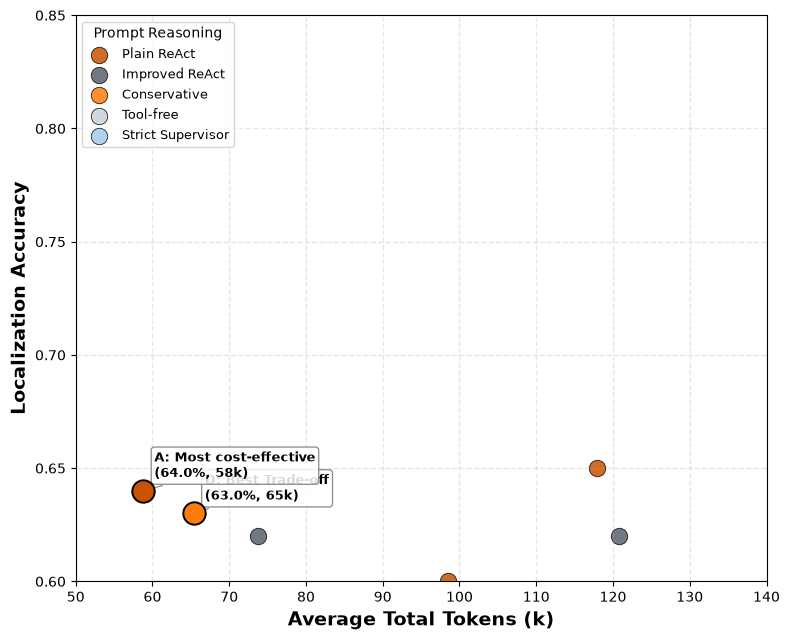

In [53]:
# Scatter Plot: Il Trade-off Efficienza vs Accuratezza
import matplotlib.pyplot as plt
import numpy as np

# Map agent IDs to prompt reasoning categories
CATEGORY_MAP = {
    'A': 'Plain ReAct',
    'B': 'Plain ReAct',
    'C': 'Plain ReAct',
    'D': 'Conservative',
    'E': 'Conservative',
    'F': 'Tool-free',
    'G': 'Tool-free',
    'H': 'Strict Supervisor',
    'I': 'Strict Supervisor',
    'J': 'Improved ReAct',
    'K': 'Improved ReAct',
    'L': 'Improved ReAct',
}

# Build agent-level summary if not already available
if 'agent_group' not in globals():
    agent_group = experiments_df.groupby('agent_id').agg(
        experiments=('experiment_file', 'count'),
        detection_accuracy=('eval_detection', 'mean'),
        localization_accuracy=('eval_localization', 'mean'),
        avg_exec_time=('execution_time_seconds', 'mean'),
        avg_tokens=('total_tokens', 'mean'),
        avg_LLM_cost=('LLM_cost', 'mean'),
        avg_rca_score=('eval_rca_score', 'mean')
    ).round(2)
    agent_group = agent_group.sort_values(['localization_accuracy', 'avg_rca_score', 'avg_tokens'], ascending=[False, False, True])

# Prepare agent-level data
plot_agents = agent_group.reset_index().copy()
plot_agents['prompt_category'] = plot_agents['agent_id'].map(CATEGORY_MAP).fillna('Other')
plot_agents['avg_tokens_k'] = plot_agents['avg_tokens'] / 1000.0

# Use cmap from palette (avoid gray ends)
categories_unique = sorted(plot_agents['prompt_category'].unique())
num_categories = len(categories_unique)
sample_points = np.linspace(0.1, 0.9, num_categories) if num_categories > 1 else np.array([0.5])
colors_array = cmap(sample_points)
category_palette = {cat: colors_array[i] for i, cat in enumerate(categories_unique)}

# Keep only categories present in data for legend ordering
category_order = [
    'Plain ReAct',
    'Improved ReAct',
    'Conservative',
    'Tool-free',
    'Strict Supervisor',
    'Other',
]
category_order = [c for c in category_order if c in plot_agents['prompt_category'].unique()]

fig, ax = plt.subplots(figsize=(8, 6.5))

# Plot all agents by category
for category in category_order:
    data = plot_agents[plot_agents['prompt_category'] == category]
    ax.scatter(
        data['avg_tokens_k'],
        data['localization_accuracy'],
        s=140,
        color=category_palette.get(category, '#7f7f7f'),
        alpha=0.85,
        edgecolors='black',
        linewidth=0.6,
        label=category
    )

# Highlight key agents with values
highlights = {
    'G': ('Highest Accuracy', (-15, 10)),
    'D': ('Best Trade-off', (8, 10)),
    'A': ('Most cost-effective', (8, 10)),
}

for agent_id, (label, offset) in highlights.items():
    row = plot_agents[plot_agents['agent_id'] == agent_id]
    if not row.empty:
        x = row['avg_tokens_k'].iloc[0]
        y = row['localization_accuracy'].iloc[0]
        acc = row['localization_accuracy'].iloc[0]
        tokens = row['avg_tokens'].iloc[0]
        
        ax.scatter(x, y, s=260, color=category_palette.get(CATEGORY_MAP.get(agent_id, 'Other'), '#7f7f7f'),
                   edgecolors='black', linewidth=1.4, zorder=5)
        ax.annotate(
            f"{agent_id}: {label}\n({acc:.1%}, {int(tokens/1000)}k)",
            (x, y),
            textcoords="offset points",
            xytext=offset,
            ha='right' if offset[0] < 0 else 'left',
            fontsize=9,
            fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', alpha=0.85, edgecolor='gray'),
            arrowprops=dict(arrowstyle='->', color='gray', lw=0.8)
        )

# Axes and title
if SHOW_TITLE:
    ax.set_title('Token Efficiency vs Accuracy Trade-off', fontsize=FONT_SIZE_TITLE, fontweight='bold')
ax.set_xlabel('Average Total Tokens (k)', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')
ax.set_ylabel('Localization Accuracy', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')

ax.set_xlim(50, 140)
ax.set_ylim(0.6, 0.85)
ax.grid(True, alpha=0.3, linestyle='--', linewidth=1)

# Legend in upper left
ax.legend(title='Prompt Reasoning', loc='upper left', fontsize=9, title_fontsize=10)

plt.tight_layout()
if SAVE_IMAGES:
    plot_counter += 1
    filename = os.path.join(plots_dir, f'{plot_counter:03d}_scatter_efficiency_vs_accuracy.pdf')
    fig.savefig(filename, format='pdf', bbox_inches='tight')
    print(f"Saved plot to {filename}")
plt.show()

Saved plot to /Users/martinimarcello00/github-sync/SRE-agent/Results/all-apps-no-ablation-A-L/plots/011_scatter_time_efficiency_vs_accuracy.pdf


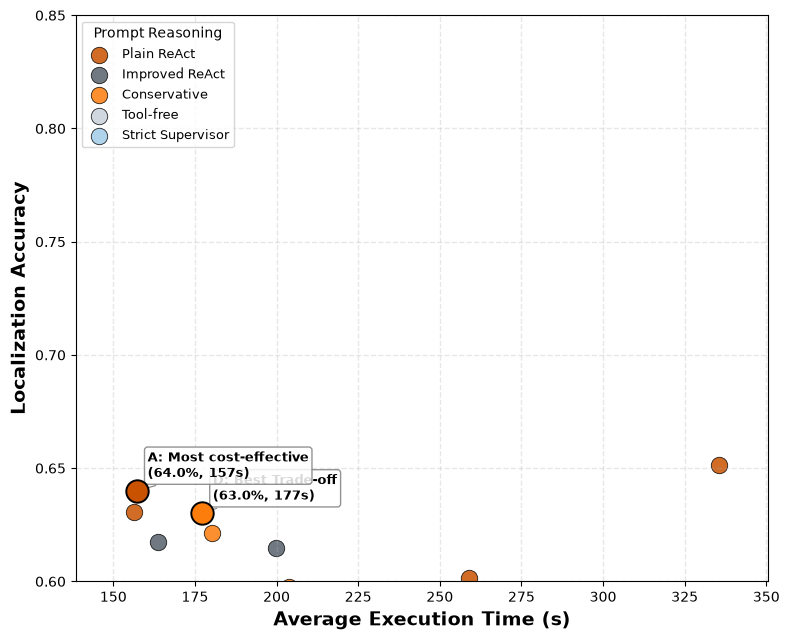

In [54]:
# Scatter Plot: Time Efficiency vs Accuracy Trade-off
import matplotlib.pyplot as plt
import numpy as np

# Reuse existing agent summary and palette
plot_agents_time = plot_agents.copy()
plot_agents_time['avg_exec_time_s'] = plot_agents_time['avg_exec_time']

# Add jitter to separate overlapping points
np.random.seed(42)
jitter_x_time = np.random.normal(0, 5.0, len(plot_agents_time))
jitter_y_time = np.random.normal(0, 0.005, len(plot_agents_time))

plot_agents_time['avg_exec_time_jit'] = plot_agents_time['avg_exec_time_s'] + jitter_x_time
plot_agents_time['localization_accuracy_jit'] = plot_agents_time['localization_accuracy'] + jitter_y_time

fig, ax = plt.subplots(figsize=(8, 6.5))

# Plot all agents by category with jitter
for category in category_order:
    data = plot_agents_time[plot_agents_time['prompt_category'] == category]
    ax.scatter(
        data['avg_exec_time_jit'],
        data['localization_accuracy_jit'],
        s=140,
        color=category_palette.get(category, '#7f7f7f'),
        alpha=0.85,
        edgecolors='black',
        linewidth=0.6,
        label=category
    )

# Highlight key agents with values
highlights = {
    'G': ('Highest Accuracy', (-15, 10)),
    'D': ('Best Trade-off', (8, 10)),
    'A': ('Most cost-effective', (8, 10)),
}

for agent_id, (label, offset) in highlights.items():
    row = plot_agents_time[plot_agents_time['agent_id'] == agent_id]
    if not row.empty:
        x = row['avg_exec_time_s'].iloc[0]
        y = row['localization_accuracy'].iloc[0]
        acc = row['localization_accuracy'].iloc[0]
        time_s = row['avg_exec_time_s'].iloc[0]

        ax.scatter(x, y, s=260, color=category_palette.get(CATEGORY_MAP.get(agent_id, 'Other'), '#7f7f7f'),
                   edgecolors='black', linewidth=1.4, zorder=5)
        ax.annotate(
            f"{agent_id}: {label}\n({acc:.1%}, {time_s:.0f}s)",
            (x, y),
            textcoords="offset points",
            xytext=offset,
            ha='right' if offset[0] < 0 else 'left',
            fontsize=9,
            fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', alpha=0.85, edgecolor='gray'),
            arrowprops=dict(arrowstyle='->', color='gray', lw=0.8)
        )

# Axes and title
if SHOW_TITLE:
    ax.set_title('Time Efficiency vs Accuracy Trade-off', fontsize=FONT_SIZE_TITLE, fontweight='bold')
ax.set_xlabel('Average Execution Time (s)', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')
ax.set_ylabel('Localization Accuracy', fontsize=FONT_SIZE_AXIS_LABELS, fontweight='bold')

# Dynamic x-limits with padding
x_min = plot_agents_time['avg_exec_time_s'].min()
x_max = plot_agents_time['avg_exec_time_s'].max()
pad = (x_max - x_min) * 0.1 if x_max > x_min else 10
ax.set_xlim(x_min - pad, x_max + pad)
ax.set_ylim(0.6, 0.85)
ax.grid(True, alpha=0.3, linestyle='--', linewidth=1)

# Legend in upper left
ax.legend(title='Prompt Reasoning', loc='upper left', fontsize=9, title_fontsize=10)

plt.tight_layout()
if SAVE_IMAGES:
    plot_counter += 1
    filename = os.path.join(plots_dir, f'{plot_counter:03d}_scatter_time_efficiency_vs_accuracy.pdf')
    fig.savefig(filename, format='pdf', bbox_inches='tight')
    print(f"Saved plot to {filename}")
plt.show()

In [55]:
analysis_output = Path('/Users/martinimarcello00/github-sync/SRE-agent/Results/all-apps-no-ablation-A-L/analysis')
experiments_df.to_csv(analysis_output / 'experiments.csv', index=False)
agent_group.to_csv(analysis_output / 'agent_summary.csv')
fault_group.to_csv(analysis_output / 'fault_summary.csv')
scenario_group.to_csv(analysis_output / 'application_summary.csv')
experiments_df.groupby(
    [experiments_df['scenario'].str.lower(), 'agent_id']
).agg(
    experiments=('experiment_file', 'count'),
    detection_accuracy=('eval_detection', 'mean'),
    localization_accuracy=('eval_localization', 'mean'),
    avg_exec_time=('execution_time_seconds', 'mean'),
    avg_tokens=('total_tokens', 'mean'),
    avg_LLM_cost=('LLM_cost', 'mean'),
    avg_rca_score=('eval_rca_score', 'mean'),
).to_csv(analysis_output / 'application_agent_summary.csv')
assert len(experiments_df) == 335, len(experiments_df)
assert set(experiments_df['agent_id']) == set('ABCDEFGHIJKL')
assert not experiments_df[required_evaluation_columns].isna().any().any()
print("Verified 335 analyzed experiments across all 12 configurations.")
print(scenario_group.to_string())


Verified 335 analyzed experiments across all 12 configurations.
                   experiments  detection_accuracy  localization_accuracy  avg_exec_time  avg_tokens  avg_rca_score
scenario                                                                                                           
hotel reservation          120                0.98                   0.82         269.62    71168.23           2.44
social network              84                0.90                   0.48         258.62   115168.01           2.20
astronomy shop             131                0.72                   0.47         140.39   111829.56           2.37
